In [381]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import numpy as np
from pathlib import Path

### Merging evaluation systems results

In [382]:
# Repository root: the first folder with settings.gradle.kts, from the working directory up
repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "settings.gradle.kts").exists())
# The results of the evaluation, collected from the machines and merged (evaluation/collect_results.sh)
statistics_path = os.path.join(repo_root, "results", "merged")
figures_path = os.path.join(repo_root, "evaluation", "figures", "merged")
os.makedirs(figures_path, exist_ok=True)
# numMachines of the single-machine ingestion runs
single_machine = 1

In [383]:
ingestion_statistics = pd.read_csv(os.path.join(statistics_path, "ingestion_statistics.csv"))
query_statistics = pd.read_csv(os.path.join(statistics_path, "query_statistics.csv"))
# The only cleaning: the same id for the same query in every system, Q1, Q2, ... (Q1Neo4J, Q1PGAge, Q1Graphix,
# Q1HyGraph -> Q1; the SmartBench names -> Q1, ..., Q6)
query_names = {
    "EnvironmentCoverage": "Q1",
    "EnvironmentAggregate": "Q2",
    "MaintenanceOwners": "Q3",
    "EnvironmentAlert": "Q4",
    "EnvironmentOutlier": "Q4",
    "AgentOutlier": "Q5",
    "AgentHistory": "Q6"
}
query_statistics["queryid"] = query_statistics["queryid"].str.replace(r"(Neo4J|PGAge|Graphix|HyGraph)$", "", regex=True).replace(query_names)
ingestion_statistics["datasetSize"] = ingestion_statistics["datasetSize"].apply(lambda x: str.capitalize(str(x)))
query_statistics["datasetSize"] = query_statistics["datasetSize"].apply(lambda x: str.capitalize(str(x)))

# All the merged results, as loaded (the cells below filter and change query_statistics and ingestion_statistics)
merged_ingestion_statistics = ingestion_statistics.copy(deep=True)
merged_query_statistics = query_statistics.copy(deep=True)

In [384]:
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
patterns = ['solid', '...', '///', '/', '|', '-', '+', 'x', 'o', 'O', '.', '*']              # hatch patterns for consistency

## Generating figures

In [385]:
import matplotlib as mpl
font = 16
colors = [ 'skyblue', 'salmon', 'lightgreen', 'orange', 'violet', 'lightsteelblue', 'gold', 'crimson', 'darkgreen', 'navy', 'saddlebrown', 'teal', 'dimgray']
patterns = ['/', '\\', 'x', 'o', '.', '*']
dataset_order = ["Small", "Medium", "Large"] #, "Extralarge"]
legend_settings = {
    "borderpad": 0.2,          # padding inside legend box
    "labelspacing": 0.2,       # vertical space between entries
    "handlelength": 1.0,       # length of legend line
    "handletextpad": 0.3,      # space between line and text
    "borderaxespad":0.2,      # space between legend and axes
    "columnspacing":0.5,       # space between columns (if multiple columns)
    "frameon":False,
    "bbox_to_anchor":(0.5, 1.1),
    "fontsize":font,
    "loc":"upper center",
}
CLIP_VALUE = 1e6 # Valore di clipping per gestire i fuori scala (es. AeonG)
fig_x = 3
fig_y = 2.5
mpl.rcParams['font.family'] = 'Times New Roman'
tableau10 = [
    "#4E79A7",  # blue
    "#F28E2B",  # orange
    "#E15759",  # red
    "#76B7B2",  # teal
    "#59A14F",  # green
    "#EDC948",  # yellow
    "#B07AA1",  # purple
    "#FF9DA7",  # pink
    "#9C755F",  # brown
    "#BAB0AC"   # gray
]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=tableau10)

def sci_format(x):
    if pd.isna(x):
        return "--"
    if not np.isfinite(x):
        return r"$\infty$"

    if x < 0:  # esecuzioni fallite, registrate come -1
        return "--"

    if x == 0:
        return "$0$"

    exponent = int(np.floor(np.log10(x)))
    mantissa = x / (10**exponent)
    return f"${mantissa:.1f} \\cdot 10^{{{exponent}}}$"

def print_latex(grouped, pivot=["dataset", "Size"], columns="Model", scinotation=True):
    grouped["datasetSize"] = pd.Categorical(grouped["datasetSize"], categories=dataset_order, ordered=True)
    latex_df = grouped \
            .rename(columns={"datasetSize": "Size", "model": "Model", "elapsedTime": "Elapsed Time (s)", "queryid": "ID"})
    latex_df["Size"] = latex_df["Size"].cat.rename_categories({"Small": "S", "Medium": "M", "Large": "L"})
    if columns is not None:
        latex_df = latex_df.pivot(index=pivot, columns=columns, values="Elapsed Time (s)")
    else:
        latex_df = latex_df.set_index(pivot)
    if scinotation:
        latex_df = latex_df.map(sci_format)
    print(latex_df.to_latex(index=True, float_format="%.1f", escape=False).replace("NaN", "--"))

def clean_df(df, numMachines=None, threads=None):
    df.replace({"1692200": "Small", "16922000": "Medium", "9223372036854775807": "Large", "Full": "Large", "full": "Large", "PGAge": "AGTS", "pgage": "AGTS", "stgraph": "STGraph"}, inplace=True) # "Large": "Medium", "Big": "Large",
    if numMachines is not None: df = df[df["numMachines"] == numMachines]
    if threads is not None: df = df[df["threads"] == threads]
    if "tsElapsedTime" in df.columns:
        df["elapsedTime"] = pd.to_numeric(df["tsElapsedTime"], errors="coerce") / 1000
    elif "elapsedTime" in df.columns:
        df["elapsedTime"] = pd.to_numeric(df["elapsedTime"], errors="coerce") / 1000
    # -------------------------
    # Dataset size filter
    # -------------------------
    size_order = ["Small", "Medium", "Large", "Extralarge"]
    df = df[df["datasetSize"].isin(size_order)].copy()
    df["datasetSize"] = (
        df["datasetSize"]
        .astype("category")
        .cat.set_categories(size_order, ordered=True)
    )
    if "graphElapsedTime" in df.columns and "tsElapsedTime" in df.columns:
        df["graphElapsedTime"] = df["graphElapsedTime"] / 1000  # Convert ms to seconds
        df["tsElapsedTime"] = df["tsElapsedTime"] / 1000  # Convert ms to seconds
    return df


Ingestion statistics

/tmp/ipykernel_1013/2614226497.py:53: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  grouped["datasetSize"] = pd.Categorical(grouped["datasetSize"], categories=dataset_order, ordered=True)


\begin{tabular}{llllll}
\toprule
 & Model & AGTS & STGraph & graphix & neo4j \\
dataset & Size &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{mimic} & S & $6.4 \cdot 10^{1}$ & $3.4 \cdot 10^{1}$ & $2.6 \cdot 10^{1}$ & $1.0 \cdot 10^{3}$ \\
 & M & $1.2 \cdot 10^{2}$ & $2.6 \cdot 10^{2}$ & $2.7 \cdot 10^{2}$ & $1.1 \cdot 10^{2}$ \\
 & L & $1.4 \cdot 10^{3}$ & $2.8 \cdot 10^{3}$ & $3.0 \cdot 10^{3}$ & $9.1 \cdot 10^{2}$ \\
\cline{1-6}
\multirow[t]{3}{*}{smartbench} & S & $2.4 \cdot 10^{2}$ & $2.2 \cdot 10^{1}$ & $2.1 \cdot 10^{1}$ & $1.3 \cdot 10^{3}$ \\
 & M & $2.6 \cdot 10^{1}$ & $7.9 \cdot 10^{1}$ & $7.8 \cdot 10^{1}$ & $1.1 \cdot 10^{2}$ \\
 & L & $9.9 \cdot 10^{2}$ & $1.7 \cdot 10^{3}$ & $1.7 \cdot 10^{3}$ & $2.3 \cdot 10^{3}$ \\
\cline{1-6}
\bottomrule
\end{tabular}



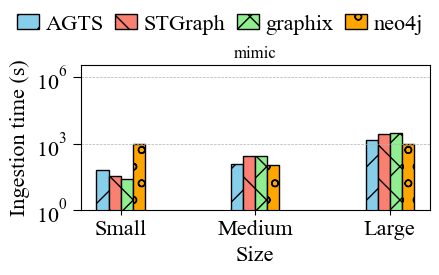

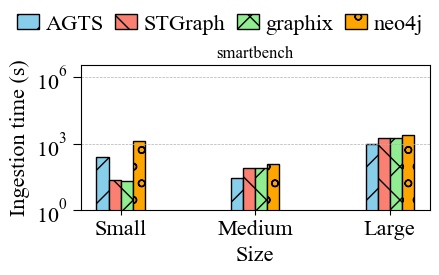

In [386]:
def print_ingestion_statistics(ingestion_statistics: pd.DataFrame):
    """
    Print ingestion statistics bar plot (log scale, clipped values, scalable patterns),
    con padding minimo sopra il limite di clipping.
    """
    import matplotlib.patches as mpatches

    df = clean_df(ingestion_statistics.copy(deep=True), threads=1, numMachines=single_machine)
    
    # df = df[~((df["model"] == "Neo4J") & (df["datasetSize"] == "Medium"))]
    grouped = df.groupby(["dataset", "datasetSize", "model"], observed=True)["elapsedTime"].mean().reset_index()
    print_latex(grouped)
    all_models = sorted(grouped["model"].unique())
    all_datasets = sorted(grouped["dataset"].unique())
    num_models = len(all_models)
    bar_width = min(0.4 / num_models, 0.09)
    x = np.arange(len(dataset_order))

    for _, dataset in enumerate(all_datasets):
        fig, ax = plt.subplots(figsize=(fig_x * 1.5, fig_y))
        for i, model in enumerate(all_models):
            offset = (i - (num_models - 1) / 2) * bar_width
            for j, ds in enumerate(dataset_order):
                subset = grouped[(grouped["datasetSize"] == ds) & (grouped["model"] == model) & (grouped["dataset"] == dataset)]
                if subset.empty:
                    continue
                if model != "STGraph" and dataset == "smartbench":  # Sottrai il tempo di processing CSV solo per i modelli diversi da STGraph su SmartBench
                    # csvTime = ((df[(df["model"] == "STGraph") & (df["datasetSize"] == ds)]["endTimestamp"] - df[(df["model"] == "STGraph") & (df["datasetSize"] == ds)]["startTimestamp"]) / 1000 - df[(df["model"] == "STGraph") & (df["datasetSize"] == ds)]["elapsedTime"]).mean()
                    csvTime = 0
                    # print(f"Average CSV processing time (s): {csvTime:.2f}")
                    #if model == "HyGraph" and dataset == "smartbench" and ds == "Medium":
                    #    value = 13.13 * 2
                    #else:
                    # print(f"STGraph elapsed time (s): {subset['elapsedTime'].values[0]:.2f}, CSV processing time (s): {csvTime:.2f}")
                    value = subset["elapsedTime"].values[0] - csvTime  # Sottrai il tempo di processing CSV
                else:
                    csvTime = 0
                    value = subset["elapsedTime"].values[0]
                # print(f"Model: {model}, Dataset: {ds}, Elapsed Time (s): {value + csvTime}, Elapsed Time - CSV (s): {value}")
                display_value = min(value, CLIP_VALUE)
                ax.bar(x[j] + offset, display_value, width=bar_width, color=colors[i % len(colors)], edgecolor='black', hatch=patterns[i % len(patterns)], label=model if j == 0 else None)
                if value >= CLIP_VALUE:
                    ax.text(x[j] + offset, CLIP_VALUE, f"X", va='center', ha='center', fontsize=font - 2, rotation=0, c="red")
                    # ax.text(x[j] + offset, CLIP_VALUE * 1.1, f"FAIL", va='bottom', ha='center', fontsize=font - 2, rotation=45, bbox=dict(facecolor='white', edgecolor='black', linewidth=0.5, alpha=0.9, pad=1.5))
                    # ax.text(x[j] + offset, CLIP_VALUE * 1.1, f"{value:.2e}", va='bottom', ha='center', fontsize=font - 2, rotation=45, bbox=dict(facecolor='white', edgecolor='black', linewidth=0.5, alpha=0.9, pad=1.5))
        ax.set_xticks(x)
        ax.set_xticklabels(dataset_order, fontsize=font)
        ax.set_xlabel("Size", fontsize=font)
        ax.set_yscale("log")
        ax.set_ylim(1, CLIP_VALUE * 3.5)
        ax.tick_params(axis='y', which='both', length=6, labelsize=font)
        ax.yaxis.grid(True, linestyle='--', linewidth=0.5, which='major')
        ax.set_ylabel("Ingestion time (s)", fontsize=font)
        handles = [
            mpatches.Patch(facecolor=colors[i % len(colors)], hatch=patterns[i % len(patterns)], edgecolor='black', label=model)
            for i, model in enumerate(all_models)
        ]
        fig.legend(handles=handles, ncol=len(all_models), **legend_settings)
        plt.title(f"{dataset}")
        plt.tight_layout()
        plt.savefig(os.path.join(figures_path, f"ingestion_statistics_{dataset}.pdf"), bbox_inches='tight')
        plt.show()

print_ingestion_statistics(ingestion_statistics)


In [387]:
def speed_up(df, group_cols = ["dataset", "datasetSize", "queryid"], column="model", baseline="STGraph", denominator=True):
    avg_times = (
        df.groupby(group_cols + [column], dropna=False, observed=True)["elapsedTime"]
        .mean()
        .reset_index()
        .rename(columns={"elapsedTime": "avgElapsedTime"})
    )
    def trimmed_mean(s):
        s = s.dropna().sort_values()
        if len(s) <= 2:
            return s.mean()
        boundary = 2 if len(s) > 4 else 1
        return s.iloc[boundary:-boundary].mean()   # drop min and max
    stgraph = (
        avg_times[avg_times[column] == baseline]
        [group_cols + ["avgElapsedTime"]]
        .rename(columns={"avgElapsedTime": baseline})
    )
    others = (
        avg_times[avg_times[column] != baseline]
        .rename(columns={
            column: "otherModel",
            "avgElapsedTime": "otherModelElapsedTime"
        })
    )
    result = others.merge(stgraph, on=group_cols, how="inner")
    result["speedup"] = (
        # result["otherModelElapsedTime"]
        # (result["otherModelElapsedTime"] - result["STGraph"]) / result["STGraph"]
        (result["otherModelElapsedTime"] / result[baseline]) if denominator else (result[baseline] / result["otherModelElapsedTime"])
        # result["STGraph"]
    )
    pivoted = (
        result.pivot_table(
            index=group_cols + [baseline],
            columns="otherModel",
            values="speedup", observed=True
        )
        .reset_index()
    )
    pivoted.columns.name = None
    pivoted = pivoted.groupby(["dataset", "datasetSize"], observed=True)[sorted([x for x in df[column].unique() if x != baseline])].agg(trimmed_mean).reset_index()
    return print_latex(pivoted, pivot=["dataset", "Size"], columns=None, scinotation=False)

speed_up(clean_df(ingestion_statistics.copy(deep=True), threads=1, numMachines=single_machine),  group_cols = ["dataset", "datasetSize"], column="model", baseline="STGraph", denominator=True)

\begin{tabular}{llrrr}
\toprule
 &  & AGTS & graphix & neo4j \\
dataset & Size &  &  &  \\
\midrule
\multirow[t]{3}{*}{mimic} & S & 1.9 & 0.8 & 29.6 \\
 & M & 0.5 & 1.0 & 0.4 \\
 & L & 0.5 & 1.1 & 0.3 \\
\cline{1-5}
\multirow[t]{3}{*}{smartbench} & S & 11.0 & 0.9 & 58.2 \\
 & M & 0.3 & 1.0 & 1.4 \\
 & L & 0.6 & 1.0 & 1.4 \\
\cline{1-5}
\bottomrule
\end{tabular}



/tmp/ipykernel_1013/2614226497.py:53: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  grouped["datasetSize"] = pd.Categorical(grouped["datasetSize"], categories=dataset_order, ordered=True)


In [388]:
def clean_df_stats(
    df,
    numMachines=None,
    threads=None,
    groupby_cols=None,
    queryMode=None,
    queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"],
    queryid_exact_match=False,
    model=None
):
    # -------------------------
    # Base cleaning
    # -------------------------
    df["numMachines"] = df["numMachines"].replace(-1, 1)
    df["numMachines"] = df["numMachines"].fillna(1).astype(int)
    df = clean_df(df, threads=threads, numMachines=numMachines)
    df["queryMode"] = df["queryMode"].fillna("OPTIMIZED")
    if queryMode is not None:
        df = df[df["queryMode"] == queryMode]
    if model is not None:
        df = df[df["model"] == model]
    # -------------------------
    # Query ID normalization
    # -------------------------
    if queryid is not None:
        if queryid_exact_match:
            df = df[df["queryid"].isin(queryid)]
        else:
            df = df[df["queryid"].apply(lambda x: len([y for y in queryid if y in x]) > 0 )]
    # -------------------------
    # Query selectivity filter
    # -------------------------
    df["querySelectivity"] = df["querySelectivity"].fillna("increased")
    df = df[(df["querySelectivity"].isna()) | (df["querySelectivity"] == "increased")]
    # -------------------------
    # Remove specific cases
    # -------------------------
    models_to_filter = ["AeonG", "HyGraph", "Neo4J"]
    df["model"] = df["model"].apply(lambda x: x.replace("neo4j", "Neo4J").replace("stgraph", "STGraph").replace("PGAge", "AGTS"))
    df = df[~(
        (df["dataset"] == "smartbench") & (df["queryid"] == "Q4") &
        df["model"].isin(models_to_filter)
    )]
    # -------------------------
    # Numeric safety
    # -------------------------
    df["elapsedTime"] = pd.to_numeric(df["elapsedTime"].fillna(-1), errors="coerce")
    df["cardinality"] = pd.to_numeric(df["cardinality"].fillna(-1), errors="coerce")
    # df = df.dropna(subset=["elapsedTime", "cardinality"])
    # -------------------------
    # Group + aggregate (dynamic)
    # -------------------------
    if groupby_cols is not None:
        df_grouped = (
            df
            .groupby(groupby_cols, as_index=False, observed=True)
            .agg({
                "elapsedTime": "mean",
                "cardinality": "mean"
            })
            .sort_values(groupby_cols)
        )
    else:
        df_grouped = df
    return df_grouped


In [389]:
speed_up(clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, queryMode="OPTIMIZED", queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q7"], queryid_exact_match=True), denominator=True)


\begin{tabular}{llrrr}
\toprule
 &  & AGTS & Neo4J & graphix \\
dataset & Size &  &  &  \\
\midrule
\multirow[t]{3}{*}{mimic} & S & 7.4 & 0.4 & 1.7 \\
 & M & 19.2 & 0.8 & 4.5 \\
 & L & 75.8 & 1.2 & 3.5 \\
\cline{1-5}
\multirow[t]{3}{*}{smartbench} & S & 2.9 & 0.3 & 1.1 \\
 & M & 1.3 & 0.5 & 2.2 \\
 & L & 8.1 & 4.8 & 10.2 \\
\cline{1-5}
\bottomrule
\end{tabular}



/tmp/ipykernel_1013/2614226497.py:53: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  grouped["datasetSize"] = pd.Categorical(grouped["datasetSize"], categories=dataset_order, ordered=True)


Query statistics - <b>different</b> selectivity across dataset size

/tmp/ipykernel_1013/2614226497.py:53: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  grouped["datasetSize"] = pd.Categorical(grouped["datasetSize"], categories=dataset_order, ordered=True)


\begin{tabular}{lllllll}
\toprule
 &  & Model & AGTS & Neo4J & STGraph & graphix \\
dataset & Size & ID &  &  &  &  \\
\midrule
\multirow[t]{9}{*}{mimic} & \multirow[t]{3}{*}{S} & Q1 & $7.0 \cdot 10^{0}$ & $1.1 \cdot 10^{0}$ & $3.3 \cdot 10^{0}$ & $4.1 \cdot 10^{0}$ \\
 &  & Q2 & $1.3 \cdot 10^{1}$ & $5.5 \cdot 10^{-1}$ & $1.8 \cdot 10^{0}$ & $3.0 \cdot 10^{0}$ \\
 &  & Q3 & $1.0 \cdot 10^{1}$ & $7.2 \cdot 10^{-1}$ & $1.1 \cdot 10^{0}$ & $2.2 \cdot 10^{0}$ \\
\cline{2-7}
 & \multirow[t]{3}{*}{M} & Q1 & $9.8 \cdot 10^{1}$ & $9.1 \cdot 10^{0}$ & $1.1 \cdot 10^{1}$ & $3.0 \cdot 10^{1}$ \\
 &  & Q2 & $1.0 \cdot 10^{2}$ & $3.8 \cdot 10^{0}$ & $5.5 \cdot 10^{0}$ & $2.6 \cdot 10^{1}$ \\
 &  & Q3 & $1.4 \cdot 10^{2}$ & $6.6 \cdot 10^{0}$ & $3.9 \cdot 10^{0}$ & $1.8 \cdot 10^{1}$ \\
\cline{2-7}
 & \multirow[t]{3}{*}{L} & Q1 & $8.7 \cdot 10^{1}$ & $8.5 \cdot 10^{1}$ & $9.2 \cdot 10^{1}$ & $1.7 \cdot 10^{4}$ \\
 &  & Q2 & $1.2 \cdot 10^{4}$ & $3.8 \cdot 10^{1}$ & $3.3 \cdot 10^{1}$ & $1.1 \cdot 1

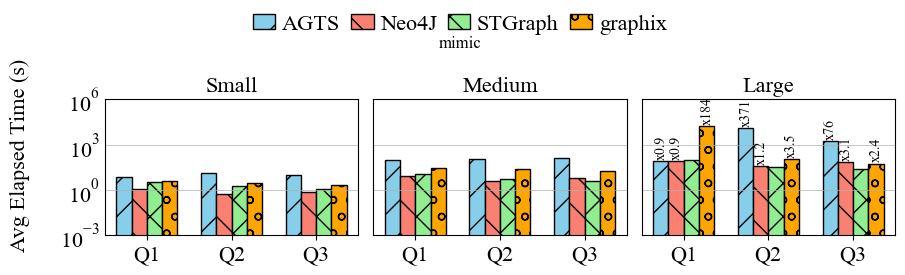

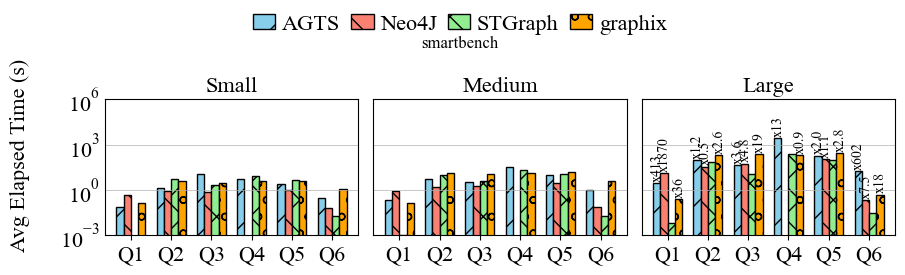

In [390]:
def print_query_statistics(query_df: pd.DataFrame):
    print_latex(query_df.dropna(subset=["elapsedTime"]).groupby(["dataset", "datasetSize", "queryid", "model"], observed=True)["elapsedTime"].mean().reset_index(), pivot=["dataset", "Size", "ID"])
    all_models = sorted(query_df["model"].unique())
    num_models = len(all_models)
    bar_width = min(0.8 / num_models, 0.18)
    for dataset in sorted(query_df["dataset"].unique()):
        fig, axes = plt.subplots(1, len(dataset_order), figsize=(fig_x * len(dataset_order), fig_y), sharey=True)
        if len(dataset_order) == 1: axes = [axes]
        for ax, ds in zip(axes, dataset_order):
            df_filtered = query_df[(query_df["dataset"] == dataset) & (query_df["datasetSize"] == ds)]
            grouped = df_filtered.groupby(["queryid", "model"], observed=True)["elapsedTime"].mean().reset_index()
            query_ids = sorted(grouped["queryid"].unique())
            x = np.arange(len(query_ids))

            for i, model in enumerate(all_models):
                values = [
                    grouped[
                        (grouped["queryid"] == q) &
                        (grouped["model"] == model)
                    ]["elapsedTime"].values[0]
                    if not grouped[
                        (grouped["queryid"] == q) &
                        (grouped["model"] == model)
                    ].empty
                    else np.nan
                    for q in query_ids
                ]

                offset = (i - (num_models - 1) / 2) * bar_width

                ax.bar(
                    x + offset,
                    values,
                    width=bar_width,
                    color=colors[i % len(colors)],
                    edgecolor="black",
                    hatch=patterns[i % len(patterns)],
                    label=model if ds == dataset_order[0] else None
                )

            # Su Large, sopra ogni barra tranne STGraph: quante volte è più lenta di STGraph sulla stessa query (es. x4.8)
            if ds == "Large" and "STGraph" in all_models:
                base = grouped[grouped["model"] == "STGraph"].set_index("queryid")["elapsedTime"]
                for i, model in enumerate(all_models):
                    if model == "STGraph":
                        continue
                    model_values = grouped[grouped["model"] == model].set_index("queryid")["elapsedTime"]
                    for j, q in enumerate(query_ids):
                        if q in model_values.index and q in base.index and model_values[q] > 0 and base[q] > 0:
                            ratio = model_values[q] / base[q]
                            ax.text(x[j] + (i - (num_models - 1) / 2) * bar_width, model_values[q] * 1.3,
                                    f"x{ratio:.0f}" if ratio >= 10 else f"x{ratio:.1f}",
                                    rotation=90, ha="center", va="bottom", fontsize=font - 6)

            # --- X axis ---
            ax.set_xticks(x)
            ax.set_xticklabels(query_ids, fontsize=font)  # tick X più grandi

            # --- Y axis ---
            ax.set_yscale("log")
            ax.set_ylim(0.001, CLIP_VALUE)
            ax.tick_params(axis="y", which="major", labelsize=font)
            ax.tick_params(axis="y", which="both", length=0)
            ax.yaxis.grid(True, which='major', linestyle='-', linewidth=0.5)
            ax.set_title(ds, fontsize=font)

        ylabel = fig.supylabel("Avg Elapsed Time (s)", fontsize=font)
        ylabel.set_position((-0.00005, 0.5))  # sposta più vicino ai tick senza sovrapporsi
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, ncol=len(all_models), **legend_settings)
        plt.suptitle(f"{dataset}")
        plt.tight_layout()  # margini ottimizzati
        plt.savefig(os.path.join(figures_path, f"query_statistics_{dataset}.svg"), bbox_inches='tight')
        plt.show()

query_df = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, queryMode="OPTIMIZED", queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q7"], queryid_exact_match=True)
print_query_statistics(query_df)

/tmp/ipykernel_1013/2614226497.py:53: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  grouped["datasetSize"] = pd.Categorical(grouped["datasetSize"], categories=dataset_order, ordered=True)


\begin{tabular}{lllllllll}
\toprule
 &  & ID & Q1 & Q2 & Q3 & Q4 & Q5 & Q6 \\
dataset & Size & queryMode &  &  &  &  &  &  \\
\midrule
\multirow[t]{5}{*}{mimic} & \multirow[t]{2}{*}{S} & NAIVE & $6.8 \cdot 10^{0}$ & $7.1 \cdot 10^{0}$ & $7.2 \cdot 10^{0}$ & -- & -- & -- \\
 &  & OPTIMIZED & $3.3 \cdot 10^{0}$ & $1.8 \cdot 10^{0}$ & $1.1 \cdot 10^{0}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{2}{*}{M} & NAIVE & $4.7 \cdot 10^{1}$ & $4.6 \cdot 10^{1}$ & $3.9 \cdot 10^{1}$ & -- & -- & -- \\
 &  & OPTIMIZED & $1.1 \cdot 10^{1}$ & $5.5 \cdot 10^{0}$ & $3.9 \cdot 10^{0}$ & -- & -- & -- \\
\cline{2-9}
 & L & OPTIMIZED & $9.2 \cdot 10^{1}$ & $3.3 \cdot 10^{1}$ & $2.3 \cdot 10^{1}$ & -- & -- & -- \\
\cline{1-9} \cline{2-9}
\multirow[t]{8}{*}{smartbench} & \multirow[t]{2}{*}{--} & NAIVE & $7.0 \cdot 10^{-3}$ & -- & -- & -- & -- & $3.7 \cdot 10^{1}$ \\
 &  & OPTIMIZED & $6.8 \cdot 10^{-3}$ & $1.6 \cdot 10^{2}$ & $2.9 \cdot 10^{0}$ & $9.5 \cdot 10^{2}$ & $1.4 \cdot 10^{2}$ & $2.4 \cdot 10^{-2}

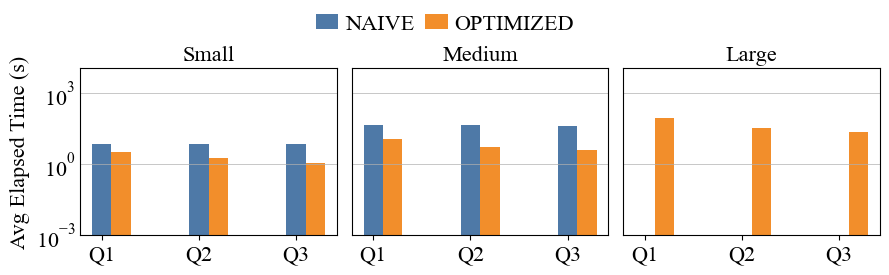

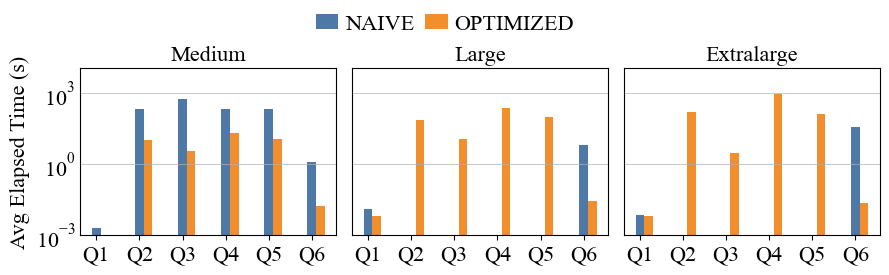

In [391]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


def plot_per_dataset(df_grouped, column="queryMode", title="opt", onlylast=False):
    datasets = df_grouped["dataset"].unique()
    print_latex(df_grouped.dropna().groupby(["dataset", "datasetSize", "queryid", column], observed=True)["elapsedTime"].mean().reset_index(), pivot=["dataset", "Size", column], columns="ID")
    for dataset in datasets:
        df_d = df_grouped[df_grouped["dataset"] == dataset]
        sizes = ["Small", "Medium", "Large", "Extralarge"]
        if title == "opt" and dataset == "smartbench":
            sizes = ["Medium", "Large", "Extralarge"]
        sizes = [s for s in sizes if s in df_d["datasetSize"].unique()]
        if onlylast:
            sizes = [sizes[-1]]
        query_ids = sorted(df_d["queryid"].unique())
        query_modes = sorted(df_d[column].unique())

        if onlylast:
            nrows, ncols = 1, 1
        else:
            nrows = 2 if len(sizes) > 3 else 1
            ncols = 3

        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=(fig_x * ncols, fig_y * nrows),
            sharey=True
        )

        axes = np.atleast_1d(axes).flatten()

        for i in range(len(sizes), len(axes)):
            axes[i].set_visible(False)

        axes = axes[:len(sizes)]

        j = 0
        for ax, size in zip(axes, sizes):
            df_s = df_d[df_d["datasetSize"] == size]

            # pivot: rows=queryid, cols=queryMode
            pivot = df_s.pivot(
                index="queryid",
                columns=column,
                values="elapsedTime"
            ).reindex(query_ids)

            x = np.arange(len(query_ids))
            width = 0.2 # 0.8 / len(query_modes)

            for i, mode in enumerate(query_modes):
                values = pivot[mode] if mode in pivot else [0]*len(query_ids)

                bars = ax.bar(
                    x + i * width,
                    values,
                    width=width,
                    label=mode
                )
            ax.set_title(f"Size: {size}")
            ax.set_xticks(x + width * (len(query_modes) - 1) / 2)
            # --- X axis ---
            ax.set_xticks(x)
            ax.set_xticklabels(query_ids, fontsize=font)  # tick X più grandi

            # --- Y axis ---
            ax.set_yscale("log")
            ax.set_ylim(0.001, 11000)
            ax.tick_params(axis="y", which="major", labelsize=font)
            ax.tick_params(axis="y", which="both", length=0)
            ax.yaxis.grid(True, which='major', linestyle='-', linewidth=0.5)
            ax.set_title(size, fontsize=font)
            if (j % 3 == 0):
                ax.set_ylabel("Avg Elapsed Time (s)", fontsize=font)
            j += 1


        # shared legend
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, ncol=len(query_modes), **legend_settings)
        # plt.suptitle(f"{dataset}")
        plt.tight_layout()  # margini ottimizzati
        plt.savefig(os.path.join(figures_path, f"query_{title}_{dataset}.pdf"), bbox_inches='tight')
        plt.show()

df_grouped = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, groupby_cols=["dataset", "datasetSize", "queryid", "queryMode"], queryid_exact_match=True, model="STGraph")
plot_per_dataset(df_grouped, title="opt", onlylast=False)

/tmp/ipykernel_1013/2614226497.py:53: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  grouped["datasetSize"] = pd.Categorical(grouped["datasetSize"], categories=dataset_order, ordered=True)


\begin{tabular}{lllllllll}
\toprule
 &  & ID & Q1 & Q2 & Q3 & Q4 & Q5 & Q6 \\
dataset & Size & threads &  &  &  &  &  &  \\
\midrule
\multirow[t]{12}{*}{mimic} & \multirow[t]{4}{*}{S} & 1 & $3.3 \cdot 10^{0}$ & $1.8 \cdot 10^{0}$ & $1.1 \cdot 10^{0}$ & -- & -- & -- \\
 &  & 4 & $4.1 \cdot 10^{-1}$ & $1.2 \cdot 10^{-1}$ & $9.3 \cdot 10^{-2}$ & -- & -- & -- \\
 &  & 8 & $4.0 \cdot 10^{-1}$ & $1.0 \cdot 10^{-1}$ & $5.4 \cdot 10^{-2}$ & -- & -- & -- \\
 &  & 16 & $6.0 \cdot 10^{-1}$ & $2.4 \cdot 10^{-1}$ & $1.3 \cdot 10^{-1}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{4}{*}{M} & 1 & $1.1 \cdot 10^{1}$ & $5.5 \cdot 10^{0}$ & $3.9 \cdot 10^{0}$ & -- & -- & -- \\
 &  & 4 & $2.1 \cdot 10^{0}$ & $7.0 \cdot 10^{-1}$ & $4.7 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 8 & $1.4 \cdot 10^{0}$ & $4.8 \cdot 10^{-1}$ & $3.2 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 16 & $1.6 \cdot 10^{0}$ & $6.5 \cdot 10^{-1}$ & $4.1 \cdot 10^{-1}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{4}{*}{L} & 1 & $9.2 \cdot 10^{

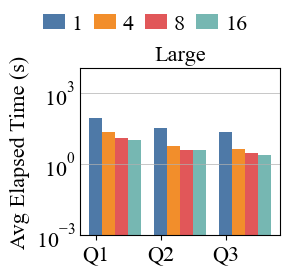

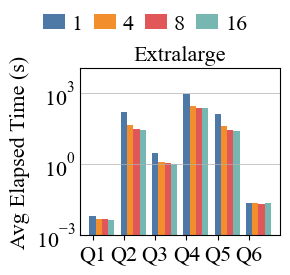

In [392]:
df_grouped = clean_df_stats(query_statistics.copy(deep=True), queryMode="OPTIMIZED", numMachines=1, groupby_cols=["dataset", "datasetSize", "queryid", "threads"], queryid_exact_match=True, model="STGraph")
plot_per_dataset(df_grouped, column="threads", title="threads", onlylast=True)

In [393]:
speed_up(df_grouped, column="threads", baseline=1, denominator=False)

\begin{tabular}{llrrr}
\toprule
 &  & 4 & 8 & 16 \\
dataset & Size &  &  &  \\
\midrule
\multirow[t]{3}{*}{mimic} & S & 12.2 & 17.0 & 7.4 \\
 & M & 7.8 & 11.4 & 8.4 \\
 & L & 5.3 & 8.0 & 8.9 \\
\cline{1-5}
\multirow[t]{4}{*}{smartbench} & S & 9.6 & 13.5 & 7.5 \\
 & M & 7.4 & 11.1 & 7.6 \\
 & L & 4.0 & 5.3 & 5.5 \\
 & -- & 2.7 & 3.3 & 3.5 \\
\cline{1-5}
\bottomrule
\end{tabular}



/tmp/ipykernel_1013/2614226497.py:53: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  grouped["datasetSize"] = pd.Categorical(grouped["datasetSize"], categories=dataset_order, ordered=True)


/tmp/ipykernel_1013/2614226497.py:53: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  grouped["datasetSize"] = pd.Categorical(grouped["datasetSize"], categories=dataset_order, ordered=True)


\begin{tabular}{lllllllll}
\toprule
 &  & ID & Q1 & Q2 & Q3 & Q4 & Q5 & Q6 \\
dataset & Size & numMachines &  &  &  &  &  &  \\
\midrule
\multirow[t]{9}{*}{mimic} & \multirow[t]{3}{*}{S} & 1 & $6.0 \cdot 10^{-1}$ & $2.4 \cdot 10^{-1}$ & $1.3 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 2 & $6.1 \cdot 10^{-1}$ & $3.3 \cdot 10^{-1}$ & $1.0 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 4 & $4.2 \cdot 10^{-1}$ & $8.5 \cdot 10^{-2}$ & $6.9 \cdot 10^{-2}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{3}{*}{M} & 1 & $1.6 \cdot 10^{0}$ & $6.5 \cdot 10^{-1}$ & $4.1 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 2 & $1.3 \cdot 10^{0}$ & $4.0 \cdot 10^{-1}$ & $2.2 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 4 & $1.1 \cdot 10^{0}$ & $3.0 \cdot 10^{-1}$ & $2.5 \cdot 10^{-1}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{3}{*}{L} & 1 & $1.0 \cdot 10^{1}$ & $4.0 \cdot 10^{0}$ & $2.5 \cdot 10^{0}$ & -- & -- & -- \\
 &  & 2 & $1.0 \cdot 10^{1}$ & $2.4 \cdot 10^{0}$ & $1.7 \cdot 10^{0}$ & -- & -- & -- \\
 &  & 4 & $9.7 \cdot 10^

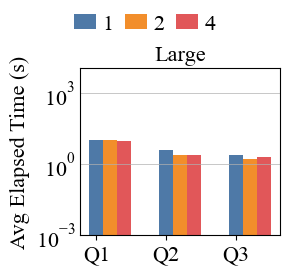

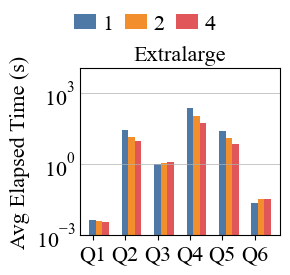

In [394]:
df_grouped = clean_df_stats(query_statistics.copy(deep=True), queryMode="OPTIMIZED", threads=16, groupby_cols=["dataset", "datasetSize", "queryid", "numMachines"], queryid_exact_match=True, model="STGraph")
plot_per_dataset(df_grouped, column="numMachines", title="numMachines", onlylast=True)

In [395]:
speed_up(df_grouped, column="numMachines", baseline=1, denominator=False)

\begin{tabular}{llrr}
\toprule
 &  & 2 & 4 \\
dataset & Size &  &  \\
\midrule
\multirow[t]{3}{*}{mimic} & S & 1.0 & 2.0 \\
 & M & 1.6 & 1.7 \\
 & L & 1.5 & 1.2 \\
\cline{1-4}
\multirow[t]{4}{*}{smartbench} & S & 1.5 & 1.9 \\
 & M & 1.5 & 1.4 \\
 & L & 1.3 & 1.2 \\
 & -- & 1.5 & 2.1 \\
\cline{1-4}
\bottomrule
\end{tabular}



/tmp/ipykernel_1013/2614226497.py:53: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  grouped["datasetSize"] = pd.Categorical(grouped["datasetSize"], categories=dataset_order, ordered=True)


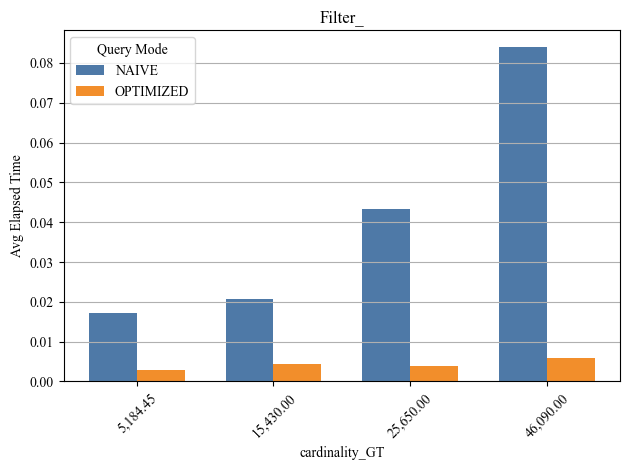

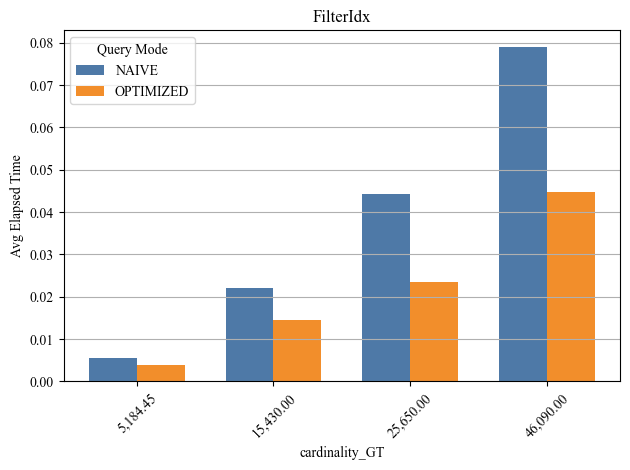

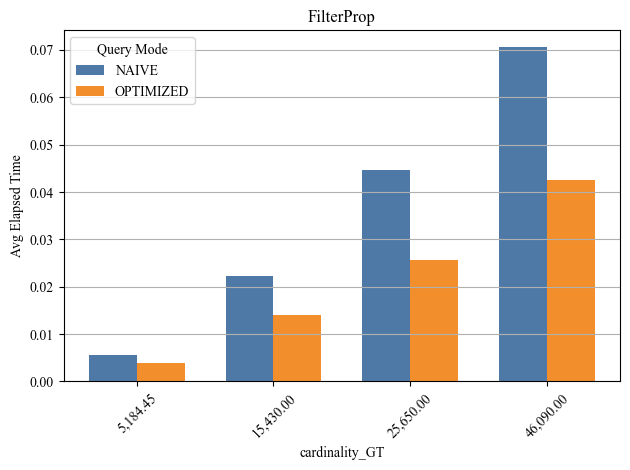

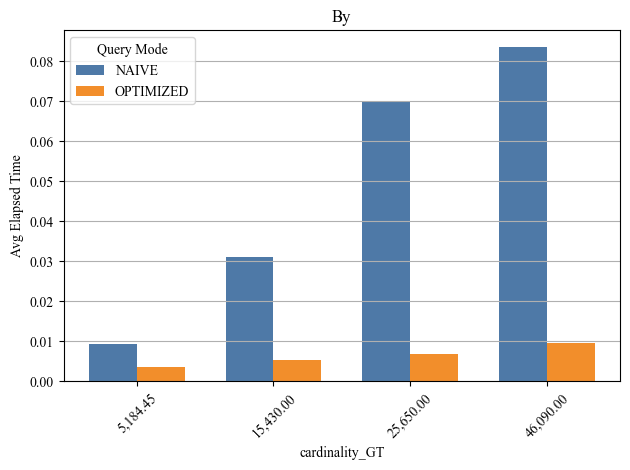

In [396]:
def plot_s(df_grouped, filter):
    for col in ["cardinality_GT"]: # , "cardinality_ratio", "cardinality"
        # --- parameters ---
        num_bins = 5

        df_grouped["card_bin"] = pd.cut(df_grouped[col], bins=num_bins)

        # df_grouped["card_bin"] = df_grouped[col]

        # aggregate
        agg = (
            df_grouped.groupby(["queryMode", "card_bin"], observed=True)
            .agg({
                "elapsedTime": "mean"
            })
            .reset_index()
        )

        # pivot → rows = bins, columns = queryModes
        pivot = agg.pivot(index="card_bin", columns="queryMode", values="elapsedTime")

        # use bin centers for labels (cleaner than intervals)
        bin_centers = [interval.mid for interval in pivot.index]

        # --- plotting ---
        x = np.arange(len(pivot))  # bin positions
        width = 0.35               # bar width

        plt.figure()

        for i, mode in enumerate(pivot.columns):
            plt.bar(
                x + i * width,
                pivot[mode],
                width=width,
                label=mode
            )

        plt.xticks(x + width * (len(pivot.columns) - 1) / 2, [f"{c:,.2f}" for c in bin_centers], rotation=45)
        plt.xlabel(col)
        plt.ylabel("Avg Elapsed Time")
        plt.title(filter)
        plt.legend(title="Query Mode")
        plt.grid(axis="y")

        plt.tight_layout()
        plt.show()

df_grouped = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, groupby_cols=["dataset", "datasetSize", "queryid", "queryMode"], queryid=["Filter_", "FilterIdx", "FilterProp", "By"])
df_grouped["cardinality_GT"] = df_grouped["queryid"].apply(lambda x: x.split("_")[2]).astype(int)
df_grouped["queryType"] = df_grouped["queryid"].apply(lambda x: x.split("_")[0])
df_grouped["cardinality_ratio"] = df_grouped["cardinality"] / df_grouped["cardinality_GT"]
df_grouped.to_csv(os.path.join(statistics_path, "query_statistics_filtered.csv"), index=False)

for filter in ["Filter_", "FilterIdx", "FilterProp", "By"]:
    df_grouped = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, groupby_cols=["dataset", "datasetSize", "queryid", "queryMode"], queryid=[filter])
    df_grouped["cardinality_GT"] = df_grouped["queryid"].apply(lambda x: x.split("_")[2]).astype(int)
    df_grouped["cardinality_ratio"] = df_grouped["cardinality"] / df_grouped["cardinality_GT"]
    plot_s(df_grouped, filter)

### Comparison by dataset and configuration

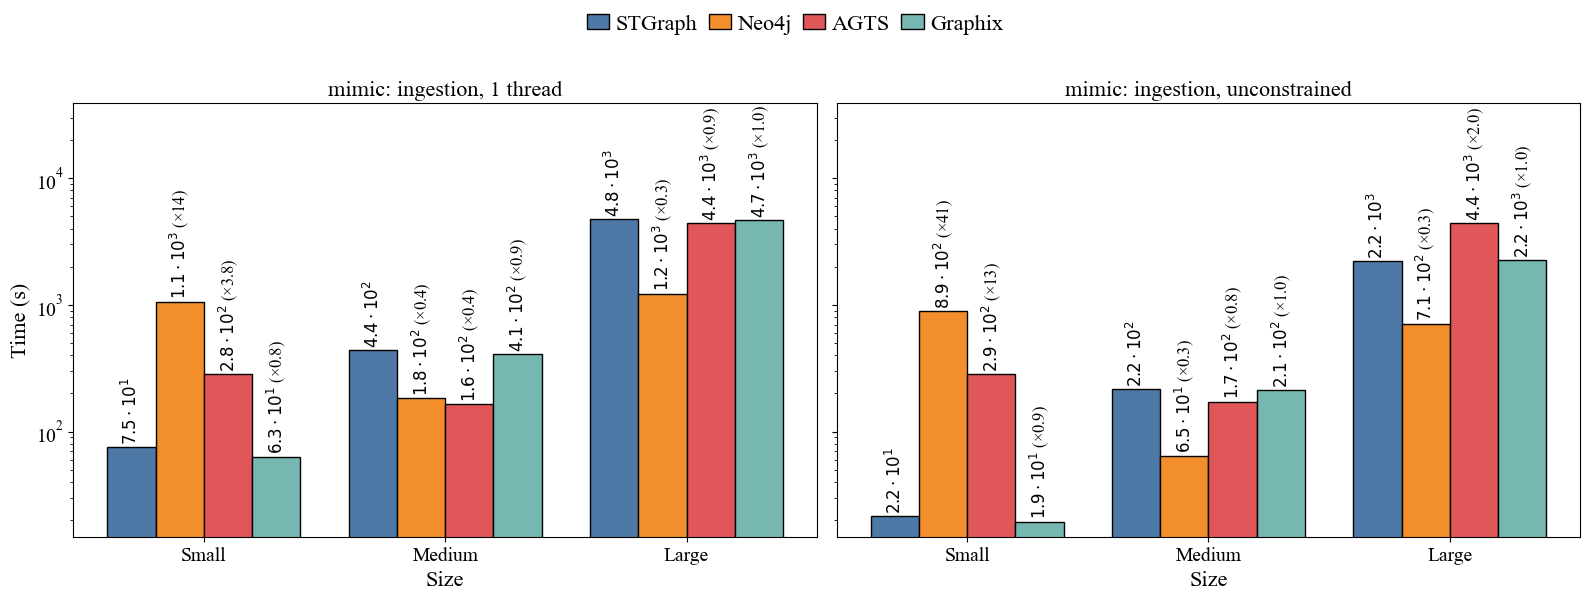

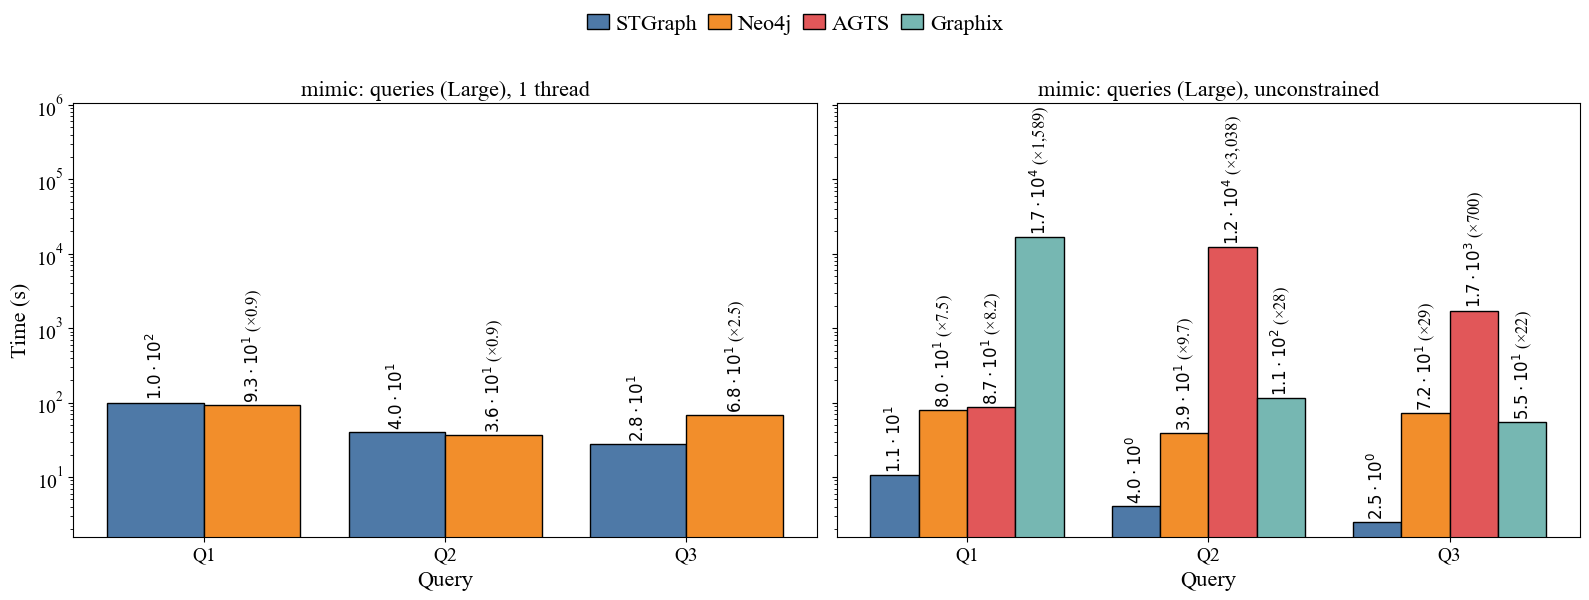

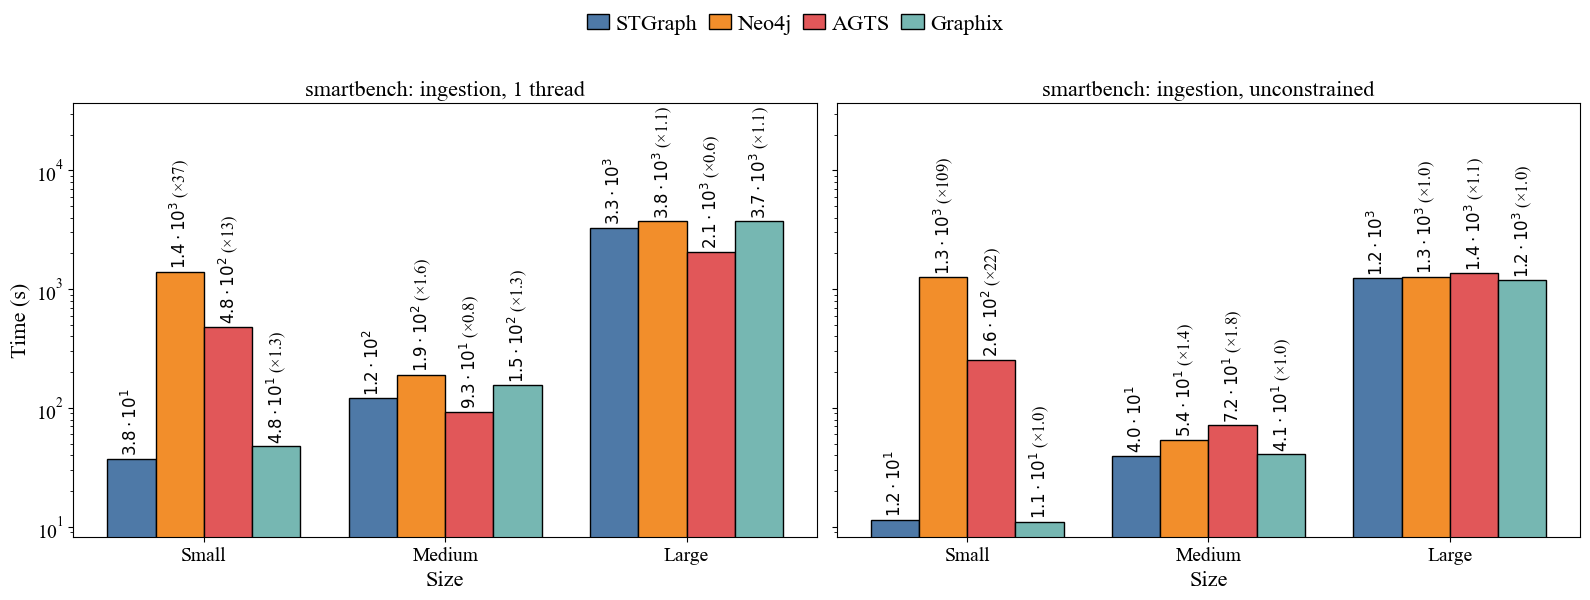

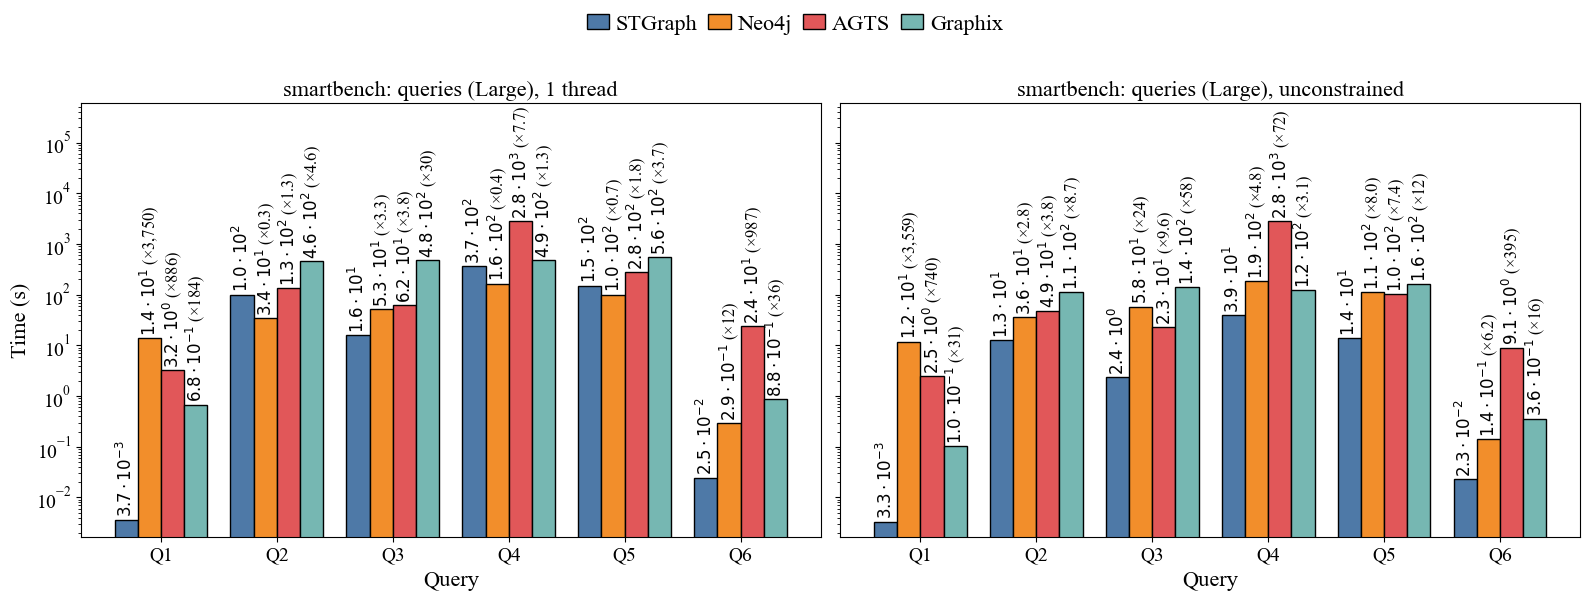

In [397]:
# Comparison charts of the merged results, configurations conf ("1 thread") and conf-free ("unconstrained"), for each
# dataset: the ingestion time, with or without the indexes (comparison_index_time) (groups: dataset sizes, columns: systems) and the query times on the Large size (groups:
# queries, columns: systems), as grouped column charts, one per configuration in the same row (same y axis); on every
# bar its time and, on the competitors, the speedup of STGraph (their time / the time of STGraph), the time in
# scientific notation: "1.2 · 10^1 (×3.8)"
comparison_configurations = ["conf", "conf-free"]
# Whether the ingestion time includes the time of the indexes (False: only the graph and the events)
comparison_index_time = False
# The names of the configurations in the charts
comparison_labels = {"conf": "1 thread", "conf-free": "unconstrained"}
comparison_systems = {"stgraph": "STGraph", "neo4j": "Neo4j", "pgage": "AGTS", "graphix": "Graphix", "hygraph": "HyGraph", "aeong": "AeonG"}
comparison_sizes = {"1692200": "Small", "16922000": "Medium", "9223372036854775807": "Large", "Full": "Large"}
comparison_size_order = ["Small", "Medium", "Large", "Extralarge"]
# The threads of STGraph in each configuration (the competitors run single-threaded)
comparison_threads = {"conf": 1, "conf-free": 16}
# The size of every figure (the row of the configurations): the same (width, height), whatever the groups and systems
comparison_figsize = (16, 6)
comparison_path = os.path.join(figures_path, "comparison")
os.makedirs(comparison_path, exist_ok=True)

def comparison_df(df):
    """The runs of the configurations, in seconds, single machine, OPTIMIZED, STGraph with the threads of its configuration"""
    df = df[df["configuration"].isin(comparison_configurations)].copy()
    df["model"] = df["model"].str.lower().map(comparison_systems).fillna(df["model"])
    df["datasetSize"] = df["datasetSize"].astype(str).replace(comparison_sizes)
    df = df[df["datasetSize"] != "Xsmall"]  # the size of the CI, not of the evaluation
    df["elapsedTime"] = pd.to_numeric(df["elapsedTime"], errors="coerce")
    if not comparison_index_time and "indexTime" in df.columns:  # the ingestion without the indexes (elapsedTime = graph + events + indexes)
        df["elapsedTime"] -= pd.to_numeric(df["indexTime"], errors="coerce").fillna(0).clip(lower=0)
    df["elapsedTime"] /= 1000
    if "queryMode" in df.columns:
        df = df[df["queryMode"].fillna("OPTIMIZED") == "OPTIMIZED"]
    if "querySelectivity" in df.columns:
        df = df[df["querySelectivity"].isna() | (df["querySelectivity"] == "increased")]
    df = df[df["numMachines"].fillna(1).replace(-1, 1) == 1]
    threads = df["configuration"].map(comparison_threads)
    return df[(df["threads"] == 1) | ((df["model"] == "STGraph") & (df["threads"] == threads))]

def comparison_number(v):
    """[v] as f.f · 10^x (mathtext)"""
    mantissa, exponent = f"{v:.1e}".split("e")
    return rf"${mantissa} \cdot 10^{{{int(exponent)}}}$"

def comparison_bars(ax, df, group, order, title):
    """The grouped column chart of df (elapsedTime in seconds) on [ax]: groups the values of [group] (in [order], then
    the others), columns the systems; the time on each bar, the speedup (time / time of STGraph) on the competitors"""
    # The bars of a group must be comparable: the same number of machines, query mode and configuration, and one number
    # of threads per system (the threads of STGraph may differ from the ones of the competitors). The machine is not
    # checked: each system may run on its own machine (same hardware)
    for keys, columns in [([group], ["numMachines", "queryMode", "configuration"]), ([group, "model"], ["threads"])]:
        columns = [c for c in columns if c in df.columns]
        mixed = df.groupby(keys)[columns].nunique(dropna=False)
        mixed = mixed[(mixed > 1).any(axis=1)]
        assert mixed.empty, f"{title}: heterogeneous {columns} in the groups\n{df[df.set_index(keys).index.isin(mixed.index)].groupby(keys + columns).size()}"
    ax.set_title(title, fontsize=font)
    times = df.groupby([group, "model"])["elapsedTime"].mean().unstack("model")
    if times.empty:
        return
    groups = [g for g in order if g in times.index] + [g for g in times.index if g not in order]
    models = [m for m in comparison_systems.values() if m in times.columns]
    times = times.reindex(index=groups, columns=models)
    width = 0.8 / len(models)
    x = np.arange(len(groups))
    for model in models:
        values = times[model].values
        i = list(comparison_systems.values()).index(model)  # the same color for a system in every chart
        bars = ax.bar(x + (models.index(model) - (len(models) - 1) / 2) * width, values, width, label=model,
                      color=tableau10[i % len(tableau10)], edgecolor="black")
        for bar, g, value in zip(bars, groups, values):
            if np.isnan(value):
                continue
            label = comparison_number(value)
            stgraph = times.at[g, "STGraph"] if "STGraph" in models else np.nan
            if model != "STGraph" and not np.isnan(stgraph) and stgraph > 0:
                speedup = value / stgraph
                label += f" (×{speedup:.1f})" if speedup < 10 else f" (×{speedup:,.0f})"
            ax.annotate(label, (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 2), textcoords="offset points",
                        ha="center", va="bottom", fontsize=font - 4, rotation=90, in_layout=False)
    ax.set_xticks(x, groups)
    ax.set_xlabel("Size" if group == "datasetSize" else "Query", fontsize=font)
    ax.tick_params(labelsize=font - 2)

def comparison_chart(df, group, order, title, file):
    """The charts of comparison_bars of df, one per configuration in the same row, with the same y axis and a legend"""
    fig, axes = plt.subplots(1, len(comparison_configurations), figsize=comparison_figsize, sharey=True)
    for ax, configuration in zip(axes, comparison_configurations):
        comparison_bars(ax, df[df["configuration"] == configuration], group, order, f"{title}, {comparison_labels[configuration]}")
    if df.empty:
        plt.close(fig)
        return
    axes[0].set_yscale("log")
    axes[0].set_ylabel("Time (s)", fontsize=font)
    handles = {l: h for ax in axes for h, l in zip(*ax.get_legend_handles_labels())}
    fig.legend(handles.values(), handles.keys(), ncol=len(handles), **{**legend_settings, "loc": "upper center", "bbox_to_anchor": (0.5, 1.0)})
    fig.tight_layout(rect=(0, 0, 1, 0.9))  # room for the legend
    # Room for the labels: the top T of the (log) y axis such that every label (of L pixels, on an axis of H pixels,
    # from the bottom b) ends inside the chart: log(value) + L / H * (T - b) <= T
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    bottom, top = np.log10(axes[0].get_ylim())
    for ax in axes:
        height = ax.get_window_extent(renderer).height
        for t in ax.texts:
            f = (t.get_window_extent(renderer).height + 4) / height
            assert f < 1, f"{title}: the labels are taller than the charts"
            top = max(top, (np.log10(t.xy[1]) - f * bottom) / (1 - f))
    axes[0].set_ylim(top=10 ** top)
    fig.savefig(os.path.join(comparison_path, file))  # not bbox_inches="tight", which would change the size
    plt.show()

comparison_ingestion = comparison_df(merged_ingestion_statistics)
comparison_query = comparison_df(merged_query_statistics)
comparison_query = comparison_query[comparison_query["queryid"].str.fullmatch(r"Q\d+") & (comparison_query["datasetSize"] == "Large")]
comparison_queries = sorted(comparison_query["queryid"].unique(), key=lambda q: int(q[1:]))
for dataset in sorted(set(comparison_ingestion["dataset"]) | set(comparison_query["dataset"])):
    comparison_chart(comparison_ingestion[comparison_ingestion["dataset"] == dataset], "datasetSize", comparison_size_order,
                     f"{dataset}: ingestion", f"{dataset}_ingestion.pdf")
    comparison_chart(comparison_query[comparison_query["dataset"] == dataset], "queryid", comparison_queries,
                     f"{dataset}: queries (Large)", f"{dataset}_queries.pdf")

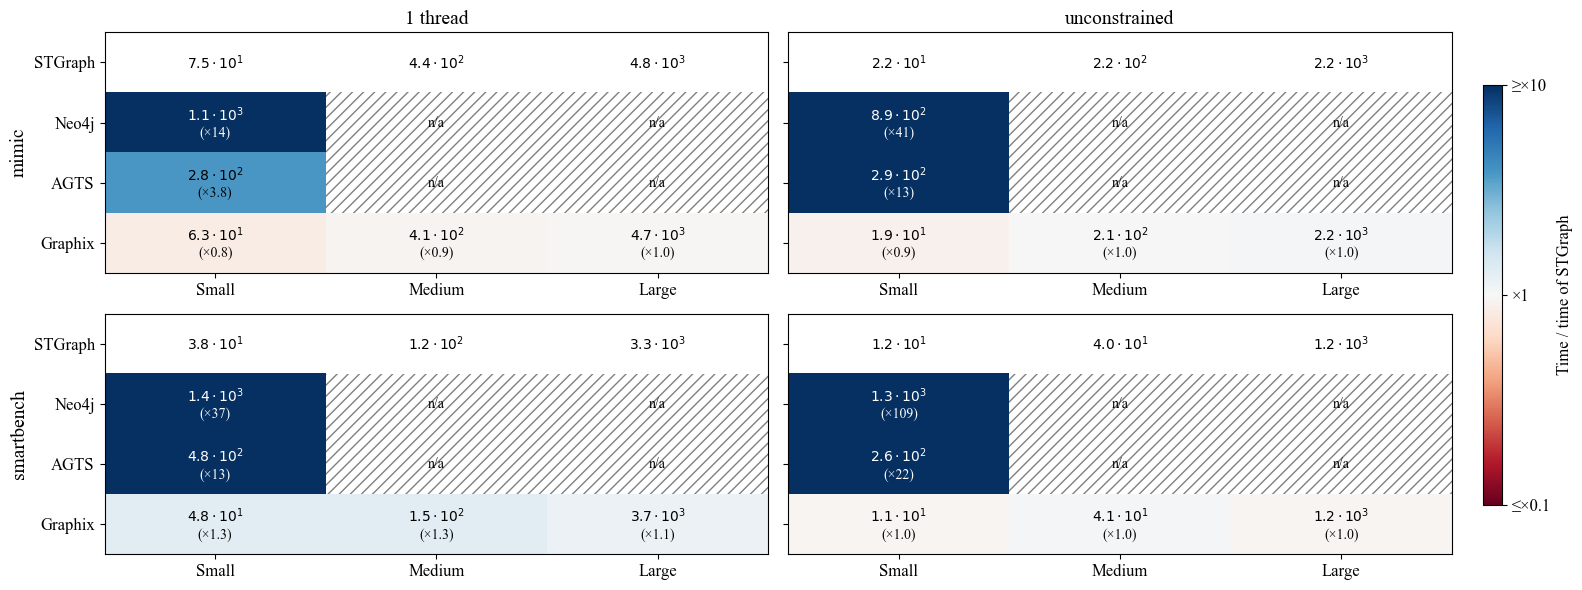

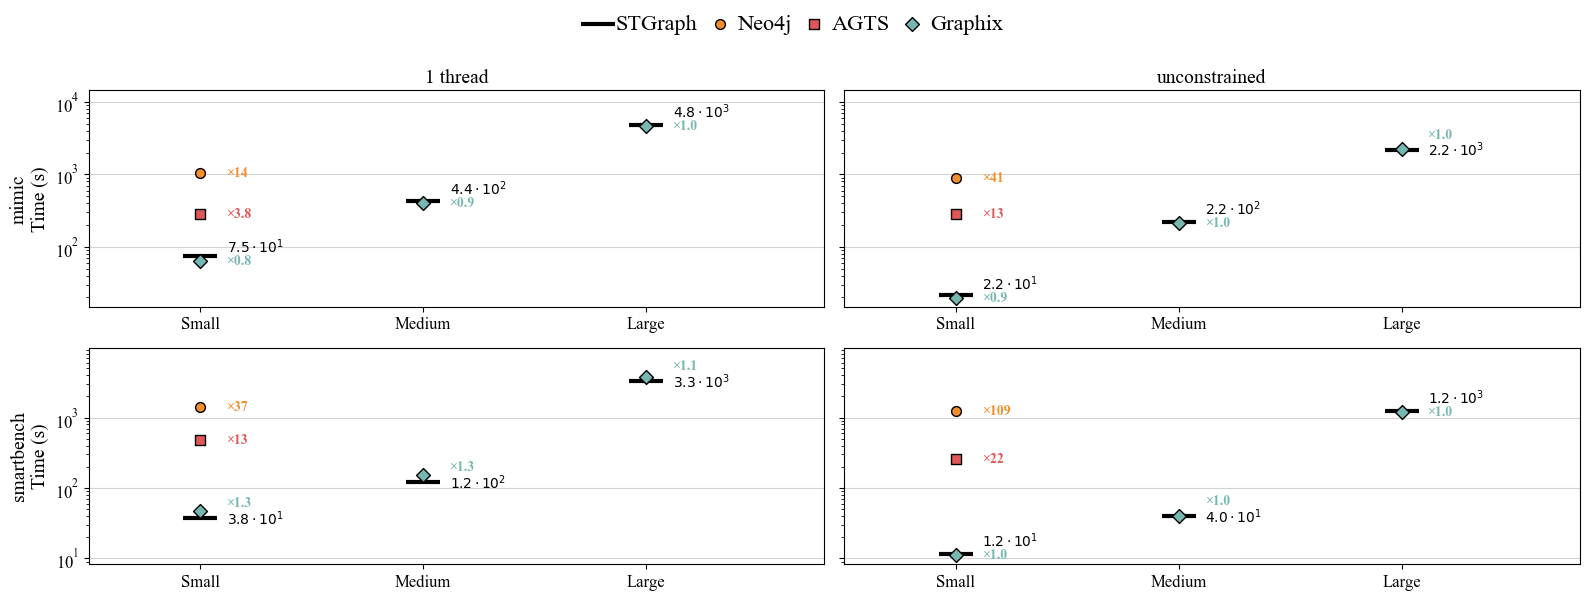

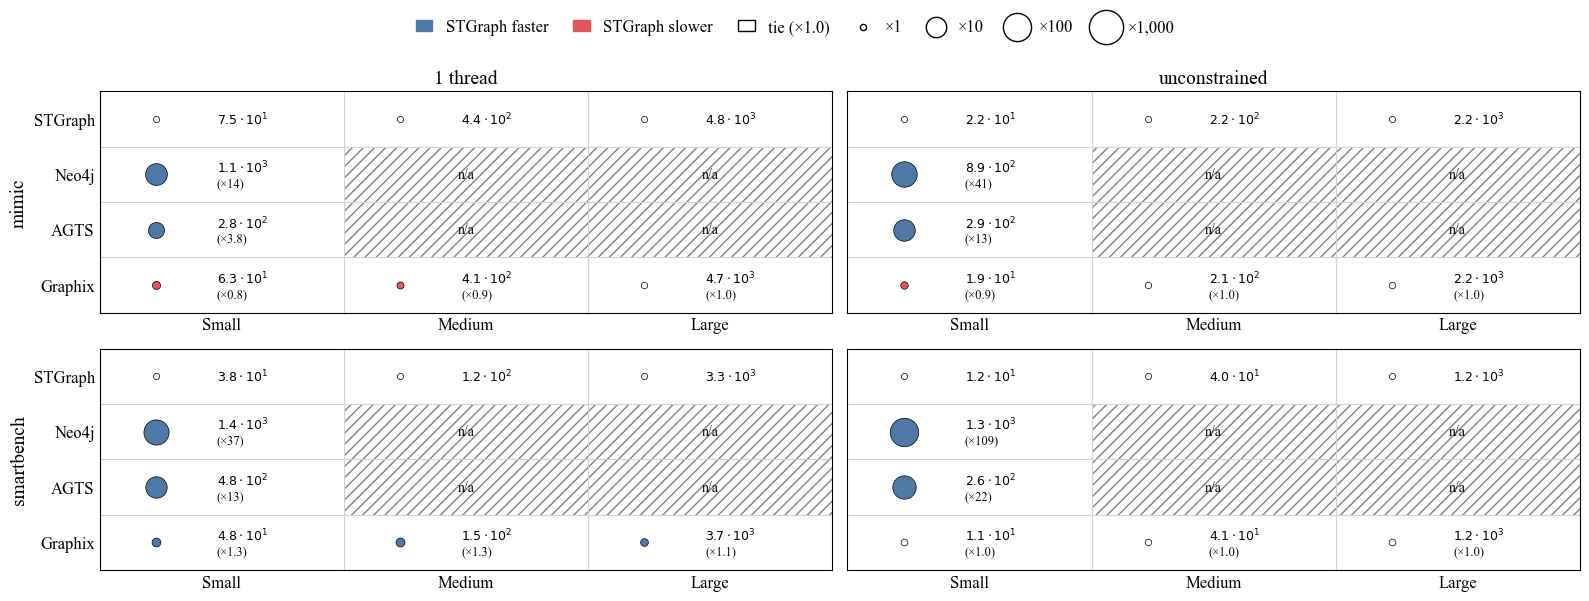

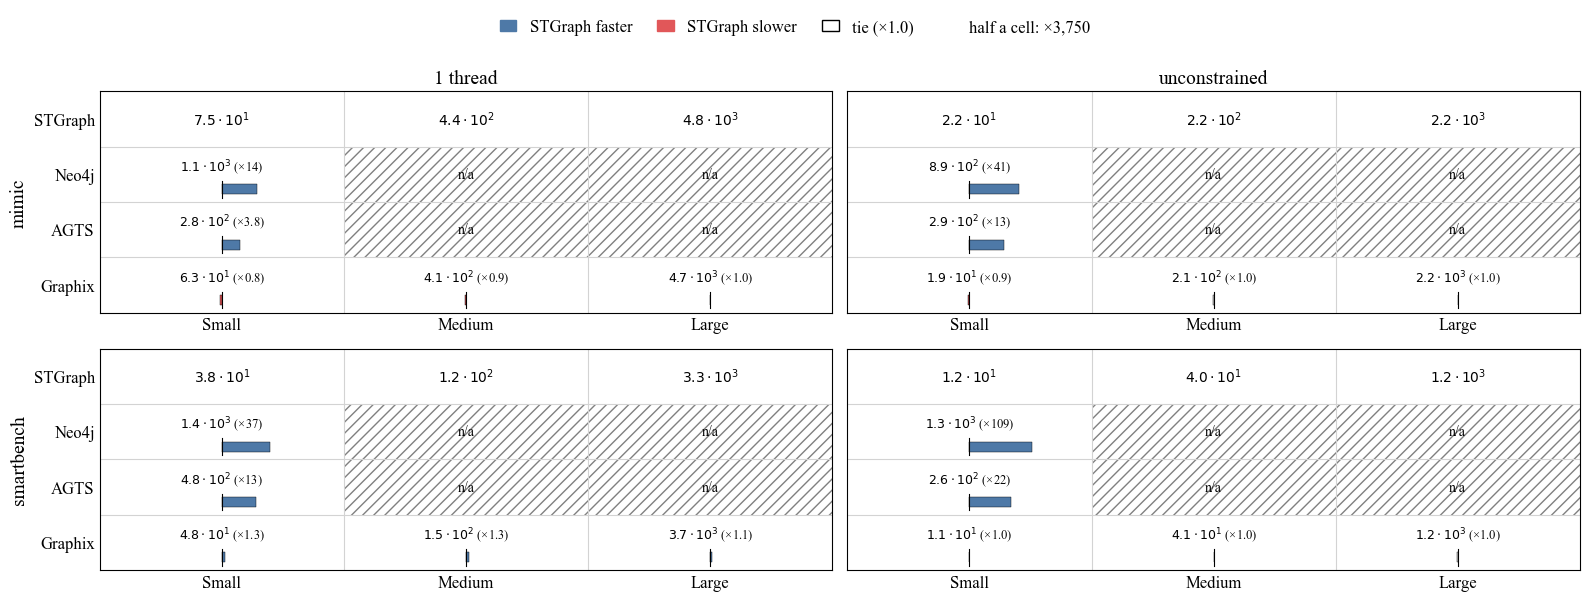

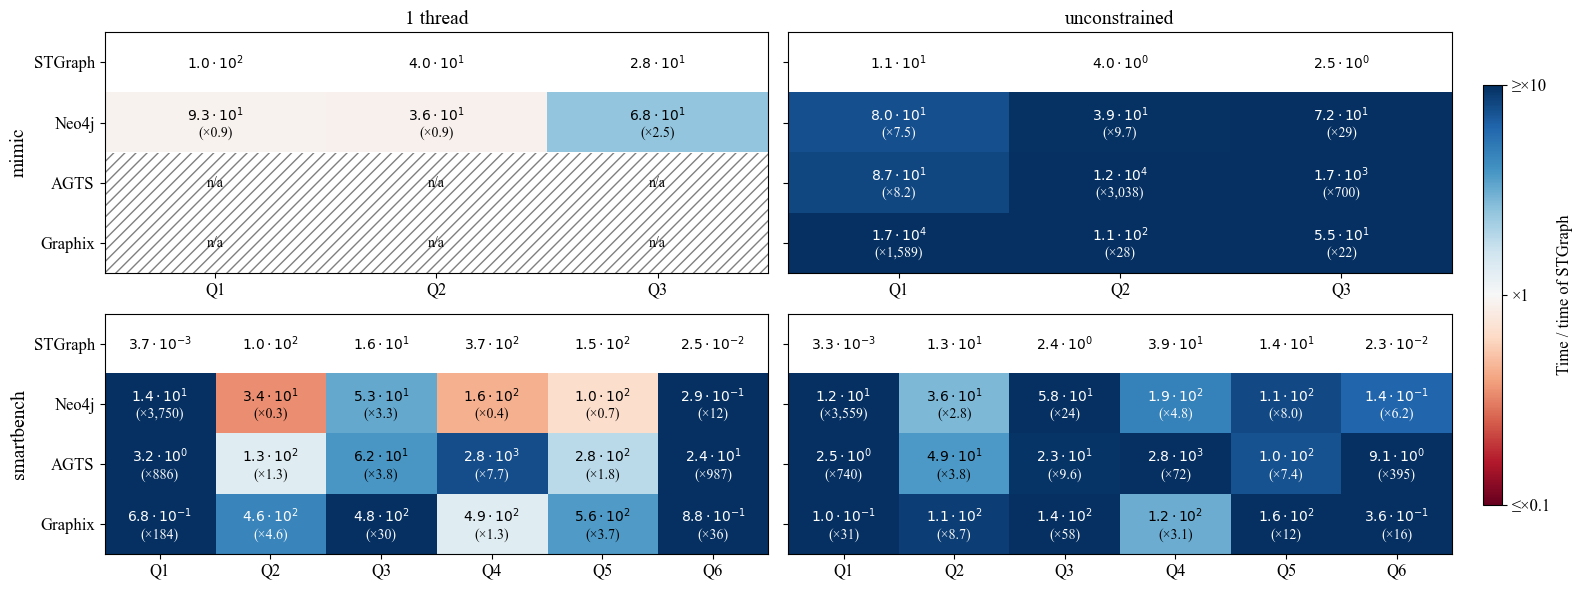

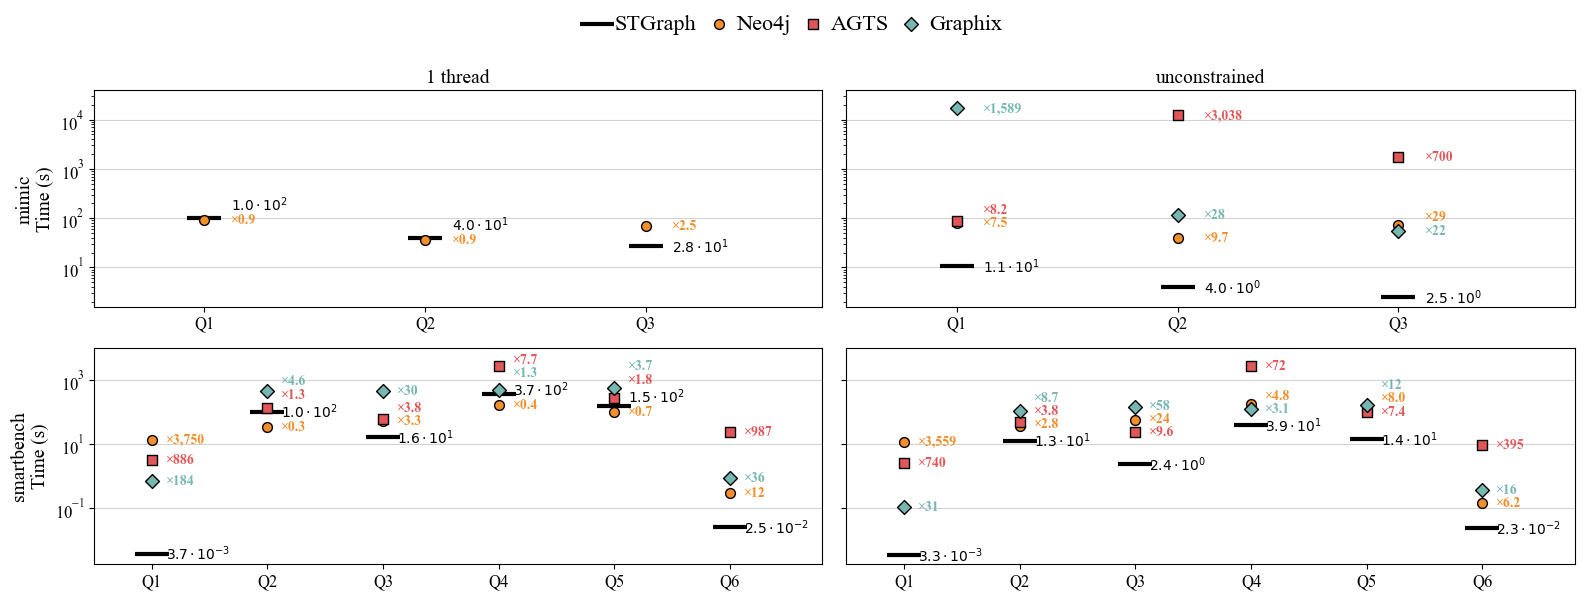

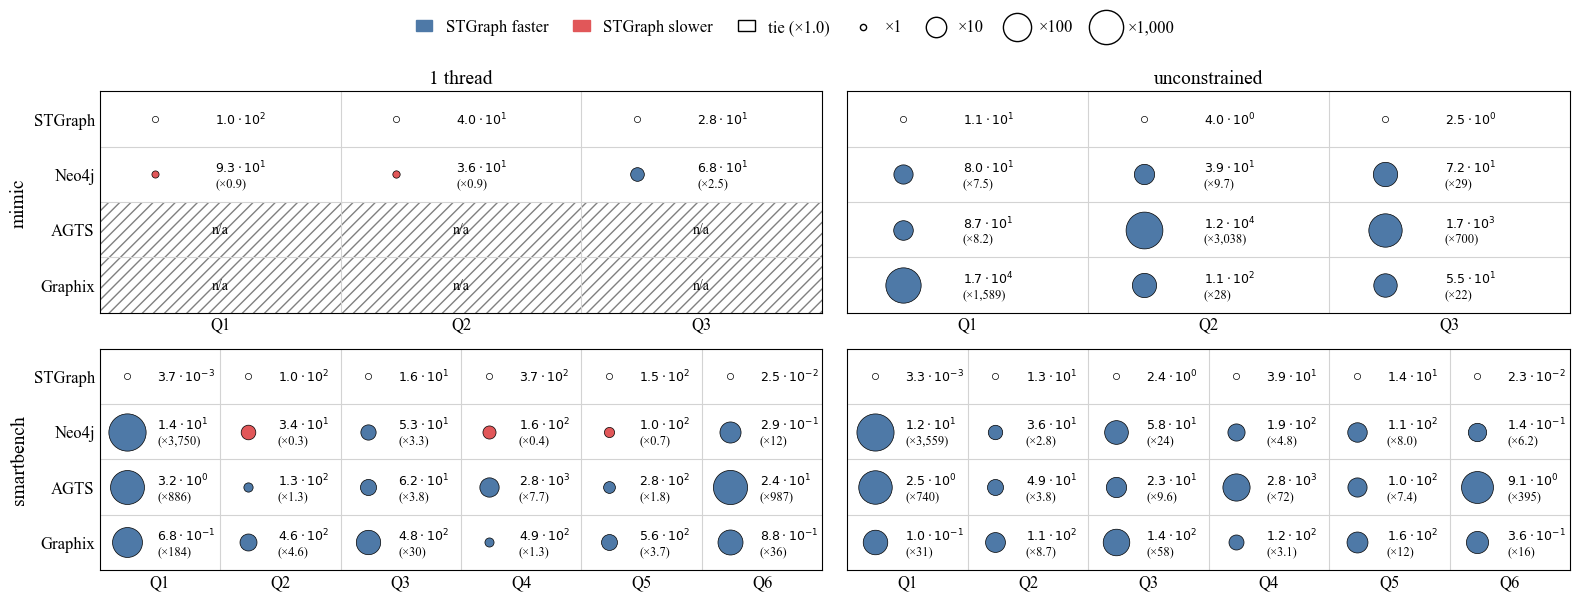

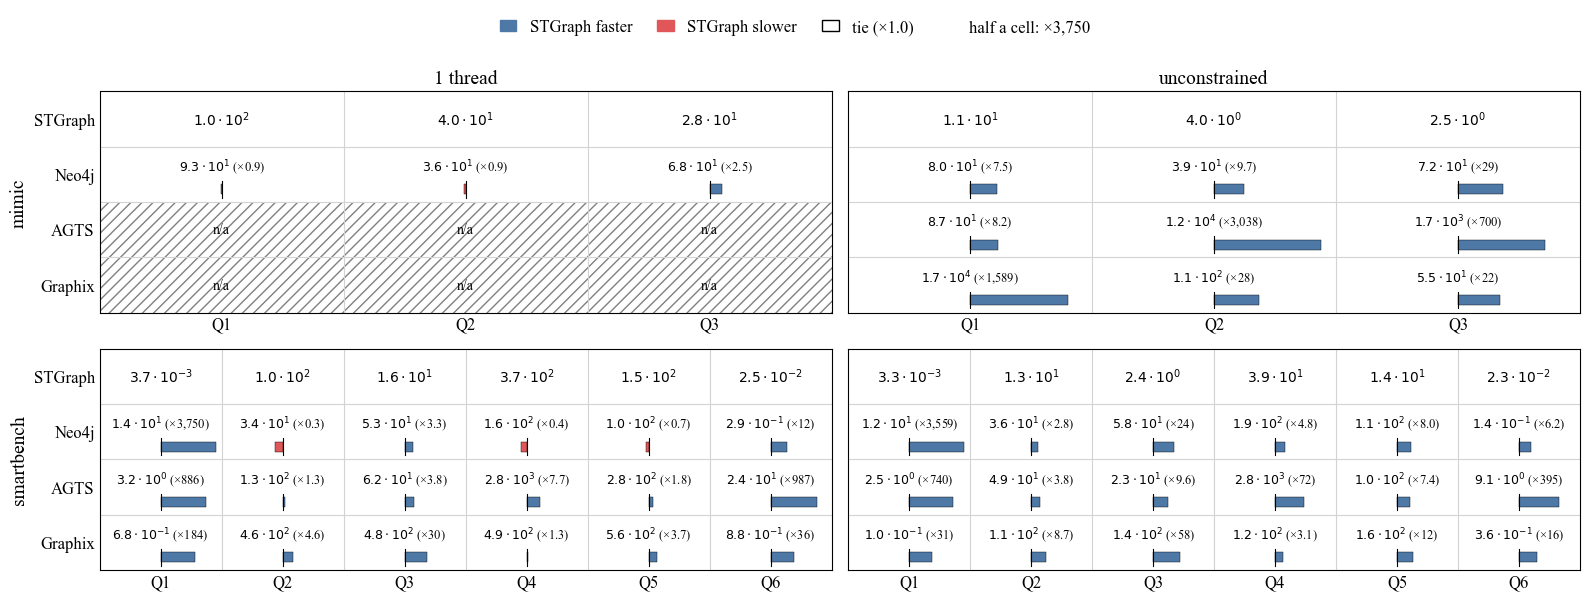

In [398]:
# The comparison in one figure for the ingestion and one for the queries, two alternatives (same data as the charts
# above: comparison_ingestion and the queries on Large): columns the datasets and their sizes or queries, systems by
# configuration ("1 thread", "unconstrained")
# - heatmap: one row per dataset, one column per configuration, rows the systems; in each cell the absolute time and,
#   for the competitors, the speedup of STGraph (time / time of STGraph), also as its color (log scale centered on 1, from x0.1 to x10: blue STGraph
#   faster, red slower; STGraph white);
# - dot plot: one row per dataset, one column per configuration, the time of each system as a marker (log scale),
#   STGraph as a black dash with its absolute time, the competitors with their speedup (in their color); the labels on
#   the right of the markers, moved up where they would overlap
# - bubbles and bars: the layout of the heatmap, the speedup as the area of a circle or the length of a bar (log scale),
#   its direction as the color (STGraph faster or slower)
# Without the ingestion from Medium on for Neo4j and AGTS (n/a)
overview_figsize = comparison_figsize  # all the figures of the comparison with the same size

def overview_times(workload):
    """Mean time (s) per (configuration, system) x (dataset, workload, size or query) of [workload] ("Ingestion" or
    "Queries (Large)"), the columns in order"""
    if workload == "Ingestion":
        df = comparison_ingestion.assign(workload=workload, item=comparison_ingestion["datasetSize"])
        # Without the ingestion from Medium on for Neo4j and AGTS
        df = df[~((df["datasetSize"] != "Small") & df["model"].isin(["Neo4j", "AGTS"]))]
    else:
        df = comparison_query.assign(workload=workload, item=comparison_query["queryid"])
    times = df.groupby(["configuration", "model", "dataset", "workload", "item"])["elapsedTime"].mean().unstack(["dataset", "workload", "item"])
    order = {s: i for i, s in enumerate(comparison_size_order + comparison_queries)}
    columns = sorted(times.columns, key=lambda c: (c[0], c[1], order.get(c[2], len(order))))
    rows = [(c, m) for c in comparison_configurations for m in comparison_systems.values() if (c, m) in times.index]
    return times.reindex(index=pd.MultiIndex.from_tuples(rows, names=["configuration", "model"]), columns=pd.MultiIndex.from_tuples(columns))

def overview_headers(ax, columns, y):
    """The dataset and workload of each group of columns, above the chart (at [y], in axes coordinates), and a line between them"""
    groups = {}
    for i, (dataset, workload, _) in enumerate(columns):
        groups.setdefault((dataset, workload), []).append(i)
    for (dataset, workload), cols in groups.items():
        ax.text((min(cols) + max(cols)) / 2, y, f"{dataset}\n{workload}", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=font - 4)
        if min(cols) > 0:
            ax.axvline(min(cols) - 0.5, color="black", linewidth=1.5)

def overview_speedups(times):
    """Time / time of STGraph in the same configuration and column (NaN for STGraph)"""
    stgraph = times.xs("STGraph", level="model")
    speedup = times / stgraph.reindex(times.index.get_level_values("configuration")).set_axis(times.index)
    speedup[times.index.get_level_values("model") == "STGraph"] = np.nan
    return speedup.astype(float)

def overview_speedup(s):
    return f"×{s:.1f}" if s < 10 else f"×{s:,.0f}"

def overview_heatmap(times, file):
    """One row per dataset, one column per configuration: rows the systems, columns the sizes or queries of the dataset;
    in each cell the absolute time and, for the competitors, the speedup, also as its color"""
    configurations = list(dict.fromkeys(times.index.get_level_values("configuration")))
    datasets = list(dict.fromkeys(times.columns.get_level_values(0)))
    speedup = overview_speedups(times)
    limit = 1  # the colors saturate at x10 and x0.1
    cmap = plt.get_cmap("RdBu").copy()
    cmap.set_bad("white")  # STGraph
    fig, axes = plt.subplots(len(datasets), len(configurations), figsize=overview_figsize, squeeze=False)
    for r, dataset in enumerate(datasets):
        columns = [c for c in times.columns if c[0] == dataset]
        for k, configuration in enumerate(configurations):
            ax = axes[r, k]
            t = times.xs(configuration, level="configuration")[columns]
            sp = speedup.xs(configuration, level="configuration")[columns]
            image = ax.imshow(np.log10(sp.values), cmap=cmap, vmin=-limit, vmax=limit, aspect="auto")
            for (i, j), value in np.ndenumerate(t.values):
                if np.isnan(value):
                    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, hatch="///", edgecolor="gray", linewidth=0))
                    ax.text(j, i, "n/a", ha="center", va="center", fontsize=font - 6)
                    continue
                s = sp.values[i, j]
                label = comparison_number(value) + ("" if np.isnan(s) else f"\n({overview_speedup(s)})")  # two lines: narrow cells
                dark = not np.isnan(s) and abs(np.log10(s)) > limit * 0.6
                ax.text(j, i, label, ha="center", va="center", fontsize=font - 6, color="white" if dark else "black")
            ax.set_xticks(range(len(columns)), [c[2] for c in columns], fontsize=font - 4)
            ax.set_yticks(range(len(t.index)), t.index if k == 0 else [], fontsize=font - 4)
            if r == 0:
                ax.set_title(comparison_labels[configuration], fontsize=font - 2)
            if k == 0:
                ax.set_ylabel(dataset, fontsize=font - 2)
    fig.tight_layout(rect=(0, 0, 0.92, 1))  # room for the color bar
    bar = fig.colorbar(image, cax=fig.add_axes((0.93, 0.15, 0.012, 0.7)))
    bar.set_ticks([-1, 0, 1], labels=["≤×0.1", "×1", "≥×10"], fontsize=font - 4)
    bar.set_label("Time / time of STGraph", fontsize=font - 4)
    fig.savefig(os.path.join(comparison_path, file))  # not bbox_inches="tight", which would change the size
    plt.show()

def overview_repel(ax, labels, gap=1):
    """Moves the labels of a column up, in order of height, so that none overlaps the one below it"""
    renderer = ax.figure.canvas.get_renderer()
    labels = sorted(labels, key=lambda t: t.get_position()[1])
    previous = None
    for t in labels:
        box = t.get_window_extent(renderer)
        if previous is not None and box.y0 < previous + gap:
            x, y = t.get_position()
            shift = previous + gap - box.y0
            _, y_display = ax.transData.transform((x, y))
            t.set_position((x, ax.transData.inverted().transform((0, y_display + shift))[1]))
            box = t.get_window_extent(renderer)
        previous = box.y1

def overview_dotplot(times, file):
    """One row per dataset, one column per configuration (the same y axis in a row): the time of each system as a marker
    (log scale), STGraph as a black dash with its absolute time, the competitors with their speedup (in their color);
    the labels on the right of the markers, moved up where they would overlap"""
    configurations = list(dict.fromkeys(times.index.get_level_values("configuration")))
    datasets = list(dict.fromkeys(times.columns.get_level_values(0)))
    speedup = overview_speedups(times)
    fig, axes = plt.subplots(len(datasets), len(configurations), figsize=overview_figsize, sharey="row", squeeze=False)
    competitors = [m for m in comparison_systems.values() if m != "STGraph" and m in times.index.get_level_values("model")]
    markers = ["o", "s", "D", "^", "v"]
    labels = {}  # (axis, column) -> the labels of the column
    for r, dataset in enumerate(datasets):
        columns = [c for c in times.columns if c[0] == dataset]
        x = np.arange(len(columns))
        for k, configuration in enumerate(configurations):
            ax = axes[r, k]
            rows = times.xs(configuration, level="configuration")[columns]
            if "STGraph" in rows.index:
                ax.scatter(x, rows.loc["STGraph"].values, marker="_", s=600, linewidths=3, color="black", label="STGraph", zorder=3)
                for c, value in enumerate(rows.loc["STGraph"].values):  # its absolute time, on the right as the speedups
                    if not np.isnan(value):
                        labels.setdefault((ax, c), []).append(ax.text(c + 0.12, value, comparison_number(value), ha="left", va="center", fontsize=font - 6))
            for i, model in enumerate(competitors):
                if model not in rows.index:
                    continue
                color = tableau10[list(comparison_systems.values()).index(model) % len(tableau10)]
                ax.scatter(x, rows.loc[model].values, marker=markers[i % len(markers)], s=50, color=color, edgecolor="black", label=model, zorder=4)
                for c, value in enumerate(rows.loc[model].values):  # the speedups, on the right, in the color of the system
                    s = speedup.loc[(configuration, model), columns].values[c]
                    if not np.isnan(s):
                        labels.setdefault((ax, c), []).append(ax.text(c + 0.12, value, overview_speedup(s), ha="left", va="center", fontsize=font - 6, color=color, fontweight="bold"))
            ax.set_yscale("log")
            ax.grid(axis="y", which="major", color="lightgray", linewidth=0.8)
            ax.set_xticks(x, [c[2] for c in columns])
            ax.set_xlim(-0.5, len(x) - 0.2)
            ax.tick_params(labelsize=font - 4)
            if r == 0:
                ax.set_title(comparison_labels[configuration], fontsize=font - 2)
            if k == 0:
                ax.set_ylabel(f"{dataset}\nTime (s)", fontsize=font - 2)
    handles = {l: h for ax in axes.flat for h, l in zip(*ax.get_legend_handles_labels())}
    fig.legend(handles.values(), handles.keys(), ncol=len(handles), **{**legend_settings, "loc": "upper center", "bbox_to_anchor": (0.5, 1.0)})
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    fig.canvas.draw()
    for (ax, _), column in labels.items():  # no overlapping labels (after the layout, which fixes the scales)
        overview_repel(ax, column)
    # The y axis of each row extended (only if needed) up to the labels moved up
    renderer = fig.canvas.get_renderer()
    for row in axes:
        top = max([row[0].get_ylim()[1]] + [ax.transData.inverted().transform((0, t.get_window_extent(renderer).y1))[1] for ax in row for t in ax.texts])
        row[0].set_ylim(top=top * 1.5)
    fig.savefig(os.path.join(comparison_path, file))
    plt.show()

def overview_cells(times, file, draw, legend, maxlog):
    """The layout of the heatmap (one row per dataset, one column per configuration; in each panel rows the systems,
    columns the sizes or queries) without colors: draw(ax, row, column, time, speedup, maxlog) draws a cell (speedup
    NaN for STGraph); maxlog: the |log10 speedup| of the largest mark (the same in every figure: the same scale);
    legend: the handles of the legend"""
    configurations = list(dict.fromkeys(times.index.get_level_values("configuration")))
    datasets = list(dict.fromkeys(times.columns.get_level_values(0)))
    speedup = overview_speedups(times)
    fig, axes = plt.subplots(len(datasets), len(configurations), figsize=overview_figsize, squeeze=False)
    for r, dataset in enumerate(datasets):
        columns = [c for c in times.columns if c[0] == dataset]
        for k, configuration in enumerate(configurations):
            ax = axes[r, k]
            t = times.xs(configuration, level="configuration")[columns]
            sp = speedup.xs(configuration, level="configuration")[columns]
            ax.set_xlim(-0.5, len(columns) - 0.5)
            ax.set_ylim(len(t.index) - 0.5, -0.5)
            for j in range(1, len(columns)):  # the borders of the cells
                ax.axvline(j - 0.5, color="lightgray", linewidth=0.8)
            for i in range(1, len(t.index)):
                ax.axhline(i - 0.5, color="lightgray", linewidth=0.8)
            for (i, j), value in np.ndenumerate(t.values):
                if np.isnan(value):
                    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, hatch="///", edgecolor="gray", linewidth=0))
                    ax.text(j, i, "n/a", ha="center", va="center", fontsize=font - 6)
                else:
                    draw(ax, i, j, value, sp.values[i, j], maxlog)
            ax.set_xticks(range(len(columns)), [c[2] for c in columns], fontsize=font - 4)
            ax.set_yticks(range(len(t.index)), t.index if k == 0 else [], fontsize=font - 4)
            ax.tick_params(length=0)
            if r == 0:
                ax.set_title(comparison_labels[configuration], fontsize=font - 2)
            if k == 0:
                ax.set_ylabel(dataset, fontsize=font - 2)
    fig.legend(handles=legend(maxlog), ncol=len(legend(maxlog)), **{**legend_settings, "fontsize": font - 4, "loc": "upper center", "bbox_to_anchor": (0.5, 1.0),
                                                                 "columnspacing": 1.5, "handletextpad": 0.8, "borderpad": 0.6})
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    fig.savefig(os.path.join(comparison_path, file))  # not bbox_inches="tight", which would change the size
    plt.show()

# The colors of the direction of the speedup: STGraph faster (speedup > 1), slower, or a tie (white: the speedup is
# x1.0 at the first decimal, as in its label)
overview_faster, overview_slower, overview_tie = tableau10[0], tableau10[2], "white"

def overview_direction(s):
    if round(s, 1) == 1.0:
        return overview_tie
    return overview_faster if s > 1 else overview_slower

def overview_direction_legend():
    return [mpatches.Patch(color=overview_faster, label="STGraph faster"), mpatches.Patch(color=overview_slower, label="STGraph slower"),
            mpatches.Patch(facecolor=overview_tie, edgecolor="black", label="tie (×1.0)")]

# Bubbles: the area of the circle grows with |log10 speedup| (x1 a dot, the largest speedup of the figure the largest circle)
overview_bubble_area = 700  # the area (points^2) of the largest circle

def overview_bubble_size(s, maxlog):
    return 20 + overview_bubble_area * abs(np.log10(s)) / maxlog  # x1 (STGraph): the smallest circle

def overview_bubble(ax, i, j, value, s, maxlog):
    if np.isnan(s):  # STGraph: the circle of x1, white as the ties, and its time
        ax.scatter(j - 0.27, i, s=overview_bubble_size(1, maxlog), color=overview_tie, edgecolor="black", linewidth=0.5, zorder=3)
        ax.text(j - 0.02, i, comparison_number(value), ha="left", va="center", fontsize=font - 7)
        return
    ax.scatter(j - 0.27, i, s=overview_bubble_size(s, maxlog), color=overview_direction(s), edgecolor="black", linewidth=0.5, zorder=3)
    ax.text(j - 0.02, i, f"{comparison_number(value)}\n({overview_speedup(s)})", ha="left", va="center", fontsize=font - 7)

def overview_bubble_legend(maxlog):
    sizes = [10 ** e for e in range(1, int(maxlog) + 1)]
    return overview_direction_legend() + [plt.scatter([], [], s=overview_bubble_size(s, maxlog), color="white", edgecolor="black", label=f"×{s:,}") for s in [1] + sizes]

# Bars: from the center of the cell, to the right if STGraph is faster, to the left if slower, the length proportional
# to |log10 speedup| (half a cell: the largest speedup of the figure)
def overview_bar(ax, i, j, value, s, maxlog):
    if np.isnan(s):  # STGraph: its time
        ax.text(j, i, comparison_number(value), ha="center", va="center", fontsize=font - 6)
        return
    ax.text(j, i - 0.12, f"{comparison_number(value)} ({overview_speedup(s)})", ha="center", va="center", fontsize=font - 7)
    length = 0.45 * np.log10(s) / maxlog
    ax.add_patch(plt.Rectangle((j, i + 0.18), length, 0.18, facecolor=overview_direction(s), edgecolor="black", linewidth=0.3, zorder=3))
    ax.plot([j, j], [i + 0.12, i + 0.42], color="black", linewidth=0.8, zorder=4)  # x1

def overview_bar_legend(maxlog):
    return overview_direction_legend() + [mpatches.Patch(color="white", label=f"half a cell: ×{10 ** maxlog:,.0f}")]

overviews = {name: overview_times(workload) for workload, name in [("Ingestion", "ingestion"), ("Queries (Large)", "queries")]}
# The same scale of the circles and of the bars in all the figures: the largest |log10 speedup| of all of them
overview_maxlog = max(1.0, max(np.nanmax(np.abs(np.log10(overview_speedups(o).values))) for o in overviews.values()))
for name, overview in overviews.items():
    overview_heatmap(overview, f"overview_heatmap_{name}.pdf")
    overview_dotplot(overview, f"overview_dotplot_{name}.pdf")
    overview_cells(overview, f"overview_bubbles_{name}.pdf", overview_bubble, overview_bubble_legend, overview_maxlog)
    overview_cells(overview, f"overview_bars_{name}.pdf", overview_bar, overview_bar_legend, overview_maxlog)